# AI-Driven Security Framework for Secure Military Information Systems

## Phase 1: Dataset Preparation and Exploratory Data Analysis

Dataset:
UNSW-NB15

Objective:
To analyze and preprocess network traffic data for developing
an AI-driven intrusion detection and security monitoring framework.

In [1]:
!pip -q install xgboost shap openpyxl

In [2]:
import os
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split

print("Libraries imported successfully!")

Libraries imported successfully!


In [4]:
import os

print("Files available in /content:\n")

for file in os.listdir("/content"):
    print(file)

Files available in /content:

.config
UNSW_NB15_training-set.csv
UNSW_NB15_testing-set.csv
sample_data


In [5]:
import pandas as pd
import numpy as np

# File paths
train_path = "/content/UNSW_NB15_training-set.csv"
test_path = "/content/UNSW_NB15_testing-set.csv"

# Load datasets
train_df = pd.read_csv(train_path)
test_df = pd.read_csv(test_path)

print("Datasets loaded successfully!")
print()
print("Training dataset shape:", train_df.shape)
print("Testing dataset shape:", test_df.shape)

Datasets loaded successfully!

Training dataset shape: (175341, 45)
Testing dataset shape: (82332, 45)


In [6]:
print("First 5 rows of training dataset:")
display(train_df.head())

First 5 rows of training dataset:


,id,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,rate,...,ct_dst_sport_ltm,ct_dst_src_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,ct_src_ltm,ct_srv_dst,is_sm_ips_ports,attack_cat,label
0,1,0.121478,tcp,-,FIN,6,4,258,172,74.087490,...,1,1,0,0,0,1,1,0,Normal,0
1,2,0.649902,tcp,-,FIN,14,38,734,42014,78.473372,...,1,2,0,0,0,1,6,0,Normal,0
2,3,1.623129,tcp,-,FIN,8,16,364,13186,14.170161,...,1,3,0,0,0,2,6,0,Normal,0
3,4,1.681642,tcp,ftp,FIN,12,12,628,770,13.677108,...,1,3,1,1,0,2,1,0,Normal,0
4,5,0.449454,tcp,-,FIN,10,6,534,268,33.373826,...,1,40,0,0,0,2,39,0,Normal,0


In [7]:
print("Column names:")
print(train_df.columns.tolist())

Column names:
['id', 'dur', 'proto', 'service', 'state', 'spkts', 'dpkts', 'sbytes', 'dbytes', 'rate', 'sttl', 'dttl', 'sload', 'dload', 'sloss', 'dloss', 'sinpkt', 'dinpkt', 'sjit', 'djit', 'swin', 'stcpb', 'dtcpb', 'dwin', 'tcprtt', 'synack', 'ackdat', 'smean', 'dmean', 'trans_depth', 'response_body_len', 'ct_srv_src', 'ct_state_ttl', 'ct_dst_ltm', 'ct_src_dport_ltm', 'ct_dst_sport_ltm', 'ct_dst_src_ltm', 'is_ftp_login', 'ct_ftp_cmd', 'ct_flw_http_mthd', 'ct_src_ltm', 'ct_srv_dst', 'is_sm_ips_ports', 'attack_cat', 'label']


In [8]:
print("Training Dataset Information")
print("=" * 60)

train_df.info()

Training Dataset Information
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 175341 entries, 0 to 175340
Data columns (total 45 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   id                 175341 non-null  int64  
 1   dur                175341 non-null  float64
 2   proto              175341 non-null  object 
 3   service            175341 non-null  object 
 4   state              175341 non-null  object 
 5   spkts              175341 non-null  int64  
 6   dpkts              175341 non-null  int64  
 7   sbytes             175341 non-null  int64  
 8   dbytes             175341 non-null  int64  
 9   rate               175341 non-null  float64
 10  sttl               175341 non-null  int64  
 11  dttl               175341 non-null  int64  
 12  sload              175341 non-null  float64
 13  dload              175341 non-null  float64
 14  sloss              175341 non-null  int64  
 15  dloss              175

In [9]:
print("\nTesting Dataset Information")
print("=" * 60)

test_df.info()


Testing Dataset Information
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 82332 entries, 0 to 82331
Data columns (total 45 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 82332 non-null  int64  
 1   dur                82332 non-null  float64
 2   proto              82332 non-null  object 
 3   service            82332 non-null  object 
 4   state              82332 non-null  object 
 5   spkts              82332 non-null  int64  
 6   dpkts              82332 non-null  int64  
 7   sbytes             82332 non-null  int64  
 8   dbytes             82332 non-null  int64  
 9   rate               82332 non-null  float64
 10  sttl               82332 non-null  int64  
 11  dttl               82332 non-null  int64  
 12  sload              82332 non-null  float64
 13  dload              82332 non-null  float64
 14  sloss              82332 non-null  int64  
 15  dloss              82332 non-null  int64 

In [10]:
print("Target columns available:")

print("label:", "label" in train_df.columns)
print("attack_cat:", "attack_cat" in train_df.columns)

Target columns available:
label: True
attack_cat: True


In [11]:
print("\nBinary classification labels:")
print(train_df["label"].value_counts())


Binary classification labels:
label
1    119341
0     56000
Name: count, dtype: int64


In [12]:
print("\nAttack categories:")
print(train_df["attack_cat"].value_counts())


Attack categories:
attack_cat
Normal            56000
Generic           40000
Exploits          33393
Fuzzers           18184
DoS               12264
Reconnaissance    10491
Analysis           2000
Backdoor           1746
Shellcode          1133
Worms               130
Name: count, dtype: int64


In [13]:
missing_values = train_df.isnull().sum()

print("Features containing missing values:")
display(
    missing_values[missing_values > 0]
)

Features containing missing values:


,0


In [14]:
print(
    "Total missing values:",
    train_df.isnull().sum().sum()
)

Total missing values: 0


In [15]:
duplicate_count = train_df.duplicated().sum()

print("Duplicate rows:", duplicate_count)

Duplicate rows: 0


In [16]:
print(
    "Duplicate rows in testing dataset:",
    test_df.duplicated().sum()
)

Duplicate rows in testing dataset: 0


In [17]:
print("Categorical columns:")

categorical_columns = train_df.select_dtypes(
    include=["object"]
).columns.tolist()

print(categorical_columns)

Categorical columns:
['proto', 'service', 'state', 'attack_cat']


In [18]:
print("\nNumerical columns:")

numerical_columns = train_df.select_dtypes(
    include=[np.number]
).columns.tolist()

print(numerical_columns)


Numerical columns:
['id', 'dur', 'spkts', 'dpkts', 'sbytes', 'dbytes', 'rate', 'sttl', 'dttl', 'sload', 'dload', 'sloss', 'dloss', 'sinpkt', 'dinpkt', 'sjit', 'djit', 'swin', 'stcpb', 'dtcpb', 'dwin', 'tcprtt', 'synack', 'ackdat', 'smean', 'dmean', 'trans_depth', 'response_body_len', 'ct_srv_src', 'ct_state_ttl', 'ct_dst_ltm', 'ct_src_dport_ltm', 'ct_dst_sport_ltm', 'ct_dst_src_ltm', 'is_ftp_login', 'ct_ftp_cmd', 'ct_flw_http_mthd', 'ct_src_ltm', 'ct_srv_dst', 'is_sm_ips_ports', 'label']


In [19]:
print(train_df["attack_cat"].unique())

['Normal' 'Backdoor' 'Analysis' 'Fuzzers' 'Shellcode' 'Reconnaissance'
 'Exploits' 'DoS' 'Worms' 'Generic']


In [20]:
print(
    train_df["attack_cat"]
    .value_counts(dropna=False)
)

attack_cat
Normal            56000
Generic           40000
Exploits          33393
Fuzzers           18184
DoS               12264
Reconnaissance    10491
Analysis           2000
Backdoor           1746
Shellcode          1133
Worms               130
Name: count, dtype: int64


In [21]:
summary = pd.DataFrame({
    "Metric": [
        "Training records",
        "Testing records",
        "Number of features",
        "Number of categorical columns",
        "Number of numerical columns",
        "Missing values",
        "Training duplicates",
        "Testing duplicates",
        "Binary classes",
        "Attack categories"
    ],
    "Value": [
        len(train_df),
        len(test_df),
        len(train_df.columns),
        len(categorical_columns),
        len(numerical_columns),
        int(train_df.isnull().sum().sum()),
        int(train_df.duplicated().sum()),
        int(test_df.duplicated().sum()),
        train_df["label"].nunique(),
        train_df["attack_cat"].nunique()
    ]
})

display(summary)

,Metric,Value
0,Training records,175341
1,Testing records,82332
2,Number of features,45
3,Number of categorical columns,4
4,Number of numerical columns,41
5,Missing values,0
6,Training duplicates,0
7,Testing duplicates,0
8,Binary classes,2
9,Attack categories,10


In [22]:
# Remove identifier column
train_model = train_df.drop(columns=["id"]).copy()
test_model = test_df.drop(columns=["id"]).copy()

print("Training shape after removing ID:", train_model.shape)
print("Testing shape after removing ID:", test_model.shape)

Training shape after removing ID: (175341, 44)
Testing shape after removing ID: (82332, 44)


In [23]:
# Binary targets
y_binary_train = train_model["label"].copy()
y_binary_test = test_model["label"].copy()

# Multiclass targets
y_multi_train = train_model["attack_cat"].copy()
y_multi_test = test_model["attack_cat"].copy()

print("Binary training target:")
print(y_binary_train.value_counts())

print("\nMulticlass training target:")
print(y_multi_train.value_counts())

Binary training target:
label
1    119341
0     56000
Name: count, dtype: int64

Multiclass training target:
attack_cat
Normal            56000
Generic           40000
Exploits          33393
Fuzzers           18184
DoS               12264
Reconnaissance    10491
Analysis           2000
Backdoor           1746
Shellcode          1133
Worms               130
Name: count, dtype: int64


In [24]:
target_columns = ["label", "attack_cat"]

X_train = train_model.drop(
    columns=target_columns
).copy()

X_test = test_model.drop(
    columns=target_columns
).copy()

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

X_train shape: (175341, 42)
X_test shape: (82332, 42)


In [25]:
categorical_features = X_train.select_dtypes(
    include=["object"]
).columns.tolist()

numerical_features = X_train.select_dtypes(
    include=[np.number]
).columns.tolist()

print("Categorical features:")
print(categorical_features)

print("\nNumber of categorical features:",
      len(categorical_features))

print("\nNumber of numerical features:",
      len(numerical_features))

Categorical features:
['proto', 'service', 'state']

Number of categorical features: 3

Number of numerical features: 39


In [26]:
for col in categorical_features:
    print("\n" + "=" * 50)
    print(col)
    print("=" * 50)
    print("Training unique values:", X_train[col].nunique())
    print("Testing unique values:", X_test[col].nunique())
    print("Top values:")
    print(X_train[col].value_counts().head(15))


proto
Training unique values: 133
Testing unique values: 131
Top values:
proto
tcp       79946
udp       63283
unas      12084
arp        2859
ospf       2595
sctp       1150
any         300
gre         225
ipv6        201
mobile      201
pim         201
swipe       201
sun-nd      201
rsvp        200
sep         193
Name: count, dtype: int64

service
Training unique values: 13
Testing unique values: 13
Top values:
service
-           94168
dns         47294
http        18724
smtp         5058
ftp-data     3995
ftp          3428
ssh          1302
pop3         1105
dhcp           94
snmp           80
ssl            56
irc            25
radius         12
Name: count, dtype: int64

state
Training unique values: 9
Testing unique values: 7
Top values:
state
INT    82275
FIN    77825
CON    13152
REQ     1991
RST       83
ECO       12
PAR        1
URN        1
no         1
Name: count, dtype: int64


In [27]:
for col in categorical_features:

    train_categories = set(X_train[col].unique())
    test_categories = set(X_test[col].unique())

    unseen = test_categories - train_categories

    print(f"{col}:")
    print("  Training categories:", len(train_categories))
    print("  Testing categories :", len(test_categories))
    print("  Unseen test categories:", unseen)

proto:
  Training categories: 133
  Testing categories : 131
  Unseen test categories: set()
service:
  Training categories: 13
  Testing categories : 13
  Unseen test categories: set()
state:
  Training categories: 9
  Testing categories : 7
  Unseen test categories: {'CLO', 'ACC'}


In [28]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

In [29]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            ),
            categorical_features
        ),
        (
            "numerical",
            StandardScaler(),
            numerical_features
        )
    ]
)

print("Preprocessing pipeline created successfully.")

Preprocessing pipeline created successfully.


In [30]:
print("Fitting preprocessing pipeline...")

X_train_processed = preprocessor.fit_transform(X_train)

print("Transforming test data...")

X_test_processed = preprocessor.transform(X_test)

print("Preprocessing completed!")

Fitting preprocessing pipeline...
Transforming test data...
Preprocessing completed!


In [31]:
print("Processed training shape:",
      X_train_processed.shape)

print("Processed testing shape:",
      X_test_processed.shape)

Processed training shape: (175341, 194)
Processed testing shape: (82332, 194)


In [32]:
feature_names = preprocessor.get_feature_names_out()

print("Number of processed features:",
      len(feature_names))

print("\nFirst 30 processed features:")

for feature in feature_names[:30]:
    print(feature)

Number of processed features: 194

First 30 processed features:
categorical__proto_3pc
categorical__proto_a/n
categorical__proto_aes-sp3-d
categorical__proto_any
categorical__proto_argus
categorical__proto_aris
categorical__proto_arp
categorical__proto_ax.25
categorical__proto_bbn-rcc
categorical__proto_bna
categorical__proto_br-sat-mon
categorical__proto_cbt
categorical__proto_cftp
categorical__proto_chaos
categorical__proto_compaq-peer
categorical__proto_cphb
categorical__proto_cpnx
categorical__proto_crtp
categorical__proto_crudp
categorical__proto_dcn
categorical__proto_ddp
categorical__proto_ddx
categorical__proto_dgp
categorical__proto_egp
categorical__proto_eigrp
categorical__proto_emcon
categorical__proto_encap
categorical__proto_etherip
categorical__proto_fc
categorical__proto_fire


In [33]:
X_train_processed_df = pd.DataFrame(
    X_train_processed,
    columns=feature_names
)

X_test_processed_df = pd.DataFrame(
    X_test_processed,
    columns=feature_names
)

display(X_train_processed_df.head())

,categorical__proto_3pc,categorical__proto_a/n,categorical__proto_aes-sp3-d,categorical__proto_any,categorical__proto_argus,categorical__proto_aris,categorical__proto_arp,categorical__proto_ax.25,categorical__proto_bbn-rcc,categorical__proto_bna,...,numerical__ct_dst_ltm,numerical__ct_src_dport_ltm,numerical__ct_dst_sport_ltm,numerical__ct_dst_src_ltm,numerical__is_ftp_login,numerical__ct_ftp_cmd,numerical__ct_flw_http_mthd,numerical__ct_src_ltm,numerical__ct_srv_dst,numerical__is_sm_ips_ports
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,-0.645013,-0.544736,-0.554373,-0.705529,-0.118590,-0.118590,-0.189768,-0.715714,-0.753074,-0.126508
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,-0.645013,-0.544736,-0.554373,-0.614256,-0.118590,-0.118590,-0.189768,-0.715714,-0.288257,-0.126508
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,-0.520827,-0.544736,-0.554373,-0.522983,-0.118590,-0.118590,-0.189768,-0.595543,-0.288257,-0.126508
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,-0.520827,-0.544736,-0.554373,-0.522983,7.814915,7.814915,-0.189768,-0.595543,-0.753074,-0.126508
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,-0.520827,-0.420468,-0.554373,2.854115,-0.118590,-0.118590,-0.189768,-0.595543,2.779535,-0.126508


In [34]:
print(
    "NaN values in training:",
    np.isnan(X_train_processed).sum()
)

print(
    "NaN values in testing:",
    np.isnan(X_test_processed).sum()
)

print(
    "Infinite values in training:",
    np.isinf(X_train_processed).sum()
)

print(
    "Infinite values in testing:",
    np.isinf(X_test_processed).sum()
)

NaN values in training: 0
NaN values in testing: 0
Infinite values in training: 0
Infinite values in testing: 0


In [35]:
import joblib

joblib.dump(
    preprocessor,
    "/content/preprocessor.pkl"
)

print("Preprocessor saved successfully.")

Preprocessor saved successfully.


In [36]:
import os

os.makedirs("/content/project_data", exist_ok=True)

np.save(
    "/content/project_data/X_train_processed.npy",
    X_train_processed
)

np.save(
    "/content/project_data/X_test_processed.npy",
    X_test_processed
)

np.save(
    "/content/project_data/y_binary_train.npy",
    y_binary_train.values
)

np.save(
    "/content/project_data/y_binary_test.npy",
    y_binary_test.values
)

print("Processed datasets saved.")

Processed datasets saved.


In [37]:
# ============================================================
# PHASE 3 — BINARY INTRUSION DETECTION
# ============================================================

# Convert processed arrays to numpy arrays
X_train_bin = X_train_processed
X_test_bin = X_test_processed

y_train_bin = y_binary_train.values
y_test_bin = y_binary_test.values

print("Binary classification dataset")
print("=" * 50)

print("X_train:", X_train_bin.shape)
print("X_test :", X_test_bin.shape)

print("\ny_train distribution:")
print(pd.Series(y_train_bin).value_counts())

print("\ny_test distribution:")
print(pd.Series(y_test_bin).value_counts())

Binary classification dataset
X_train: (175341, 194)
X_test : (82332, 194)

y_train distribution:
1    119341
0     56000
Name: count, dtype: int64

y_test distribution:
1    45332
0    37000
Name: count, dtype: int64


In [38]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from xgboost import XGBClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve
)

import time

In [39]:
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42,
        max_depth=20
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=150,
        random_state=42,
        n_jobs=-1
    ),

    "XGBoost": XGBClassifier(
        n_estimators=200,
        max_depth=8,
        learning_rate=0.1,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    )
}

print("Models created:")
for name in models:
    print("-", name)

Models created:
- Logistic Regression
- Decision Tree
- Random Forest
- XGBoost


In [40]:
results = []
trained_models = {}

for name, model in models.items():

    print("\n" + "=" * 70)
    print("Training:", name)
    print("=" * 70)

    start_time = time.time()

    # Train
    model.fit(X_train_bin, y_train_bin)

    training_time = time.time() - start_time

    # Prediction
    start_time = time.time()

    y_pred = model.predict(X_test_bin)

    prediction_time = time.time() - start_time

    # Probability for ROC-AUC
    if hasattr(model, "predict_proba"):
        y_prob = model.predict_proba(X_test_bin)[:, 1]
    else:
        y_prob = None

    # Metrics
    accuracy = accuracy_score(
        y_test_bin,
        y_pred
    )

    precision = precision_score(
        y_test_bin,
        y_pred,
        zero_division=0
    )

    recall = recall_score(
        y_test_bin,
        y_pred,
        zero_division=0
    )

    f1 = f1_score(
        y_test_bin,
        y_pred,
        zero_division=0
    )

    if y_prob is not None:
        auc = roc_auc_score(
            y_test_bin,
            y_prob
        )
    else:
        auc = np.nan

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1,
        "ROC-AUC": auc,
        "Training Time (sec)": training_time,
        "Prediction Time (sec)": prediction_time
    })

    trained_models[name] = model

    print("Training time:", round(training_time, 3), "seconds")
    print("Accuracy:", round(accuracy, 4))
    print("Precision:", round(precision, 4))
    print("Recall:", round(recall, 4))
    print("F1 Score:", round(f1, 4))
    print("ROC-AUC:", round(auc, 4))


Training: Logistic Regression
Training time: 26.101 seconds
Accuracy: 0.8091
Precision: 0.7529
Recall: 0.9723
F1 Score: 0.8487
ROC-AUC: 0.9555

Training: Decision Tree
Training time: 5.298 seconds
Accuracy: 0.8681
Precision: 0.8295
Recall: 0.9571
F1 Score: 0.8887
ROC-AUC: 0.8958

Training: Random Forest
Training time: 36.856 seconds
Accuracy: 0.8712
Precision: 0.8177
Recall: 0.9858
F1 Score: 0.8939
ROC-AUC: 0.979

Training: XGBoost
Training time: 17.994 seconds
Accuracy: 0.873
Precision: 0.8216
Recall: 0.9828
F1 Score: 0.895
ROC-AUC: 0.9834


In [41]:
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="F1 Score",
    ascending=False
).reset_index(drop=True)

display(results_df)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,Training Time (sec),Prediction Time (sec)
0,XGBoost,0.873038,0.821602,0.982816,0.895007,0.983393,17.994452,0.417833
1,Random Forest,0.871156,0.817683,0.985794,0.893903,0.979029,36.856397,2.204405
2,Decision Tree,0.868059,0.829475,0.957138,0.888746,0.895787,5.297755,0.038504
3,Logistic Regression,0.809090,0.752947,0.972293,0.848676,0.955539,26.101068,0.027749


In [42]:
results_df.to_csv(
    "/content/binary_model_comparison.csv",
    index=False
)

print("Binary model results saved.")

Binary model results saved.


In [43]:
best_model_name = results_df.iloc[0]["Model"]

best_model = trained_models[
    best_model_name
]

print("Best model based on F1-score:")
print(best_model_name)

Best model based on F1-score:
XGBoost


In [44]:
y_best_pred = best_model.predict(
    X_test_bin
)

print(
    classification_report(
        y_test_bin,
        y_best_pred,
        target_names=["Normal", "Attack"],
        digits=4
    )
)

              precision    recall  f1-score   support

      Normal     0.9723    0.7385    0.8394     37000
      Attack     0.8216    0.9828    0.8950     45332

    accuracy                         0.8730     82332
   macro avg     0.8969    0.8607    0.8672     82332
weighted avg     0.8893    0.8730    0.8700     82332



In [45]:
cm = confusion_matrix(
    y_test_bin,
    y_best_pred
)

print(cm)

[[27326  9674]
 [  779 44553]]


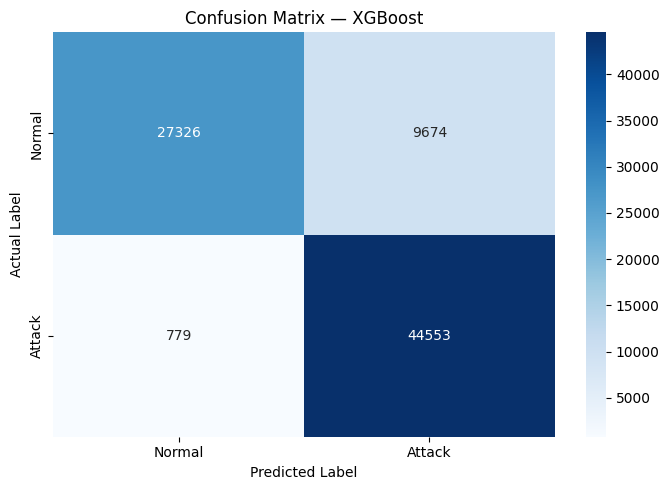

In [46]:
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Normal", "Attack"],
    yticklabels=["Normal", "Attack"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title(
    f"Confusion Matrix — {best_model_name}"
)

plt.tight_layout()

plt.savefig(
    "/content/confusion_matrix_best_model.png",
    dpi=300
)

plt.show()

In [47]:
tn, fp, fn, tp = cm.ravel()

false_positive_rate = fp / (fp + tn)

false_negative_rate = fn / (fn + tp)

print("True Negatives :", tn)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Positives :", tp)

print()
print("False Positive Rate:",
      round(false_positive_rate, 6))

print("False Negative Rate:",
      round(false_negative_rate, 6))

True Negatives : 27326
False Positives: 9674
False Negatives: 779
True Positives : 44553

False Positive Rate: 0.261459
False Negative Rate: 0.017184


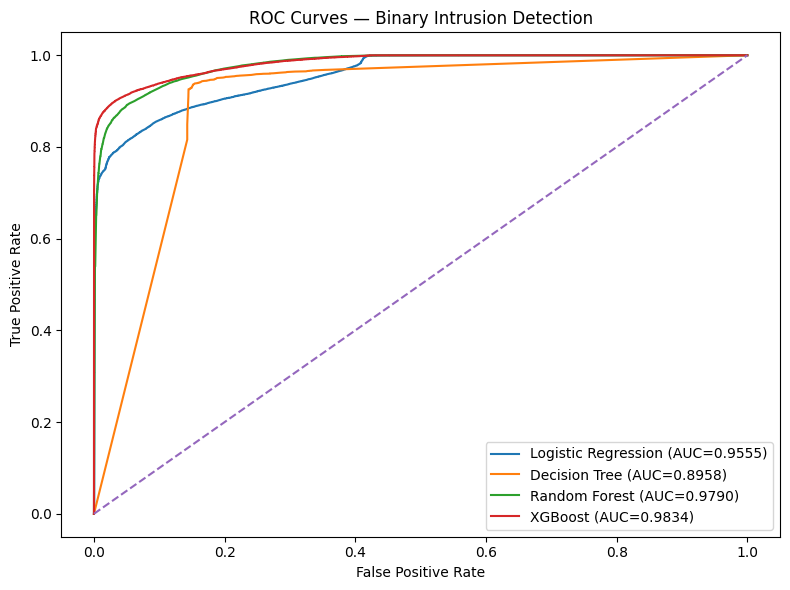

In [48]:
plt.figure(figsize=(8, 6))

for name, model in trained_models.items():

    if hasattr(model, "predict_proba"):

        y_prob = model.predict_proba(
            X_test_bin
        )[:, 1]

        fpr, tpr, _ = roc_curve(
            y_test_bin,
            y_prob
        )

        auc = roc_auc_score(
            y_test_bin,
            y_prob
        )

        plt.plot(
            fpr,
            tpr,
            label=f"{name} (AUC={auc:.4f})"
        )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title(
    "ROC Curves — Binary Intrusion Detection"
)

plt.legend()

plt.tight_layout()

plt.savefig(
    "/content/roc_curve_comparison.png",
    dpi=300
)

plt.show()

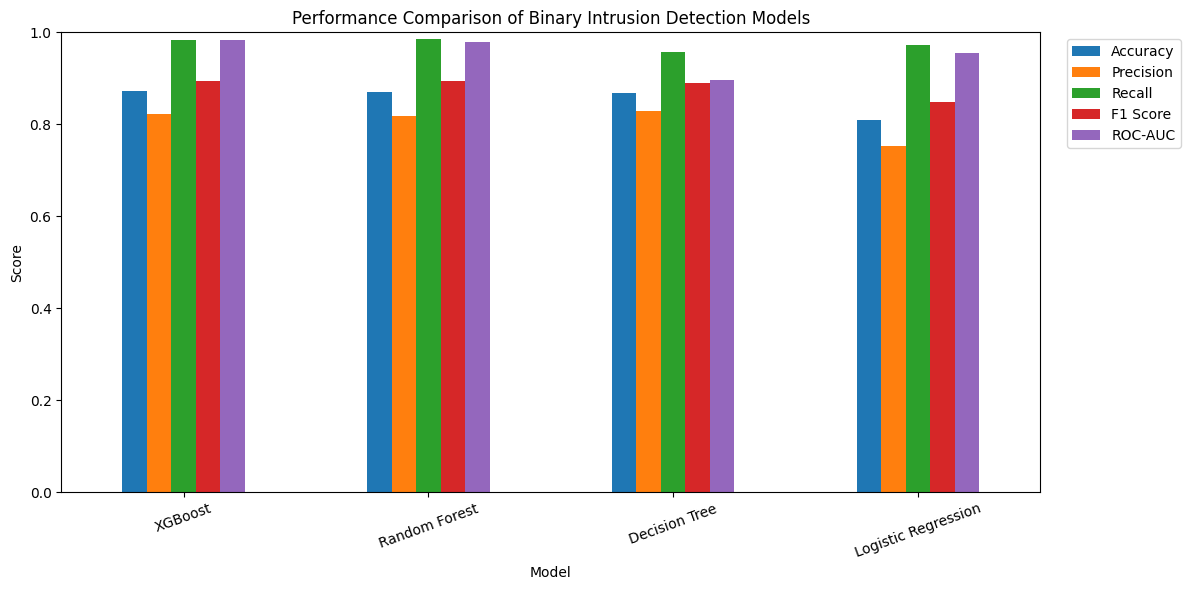

In [49]:
metrics_to_plot = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1 Score",
    "ROC-AUC"
]

results_plot = results_df.set_index("Model")[
    metrics_to_plot
]

results_plot.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title(
    "Performance Comparison of Binary Intrusion Detection Models"
)

plt.ylabel("Score")
plt.ylim(0, 1)

plt.xticks(rotation=20)

plt.legend(
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()

plt.savefig(
    "/content/model_performance_comparison.png",
    dpi=300
)

plt.show()

In [50]:
joblib.dump(
    best_model,
    "/content/best_binary_model.pkl"
)

print(
    "Best binary model saved:",
    best_model_name
)

Best binary model saved: XGBoost


In [51]:
# ============================================================
# PHASE 3B — DECISION THRESHOLD OPTIMIZATION
# ============================================================

xgb_model = trained_models["XGBoost"]

y_xgb_probability = xgb_model.predict_proba(
    X_test_bin
)[:, 1]

print("Probability predictions generated.")
print("Number of predictions:", len(y_xgb_probability))
print("Minimum probability:", y_xgb_probability.min())
print("Maximum probability:", y_xgb_probability.max())

Probability predictions generated.
Number of predictions: 82332
Minimum probability: 3.9231068e-06
Maximum probability: 0.9999927


In [52]:
threshold_results = []

thresholds = np.arange(
    0.10,
    0.91,
    0.05
)

for threshold in thresholds:

    y_threshold_pred = (
        y_xgb_probability >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_test_bin,
        y_threshold_pred
    ).ravel()

    accuracy = accuracy_score(
        y_test_bin,
        y_threshold_pred
    )

    precision = precision_score(
        y_test_bin,
        y_threshold_pred,
        zero_division=0
    )

    recall = recall_score(
        y_test_bin,
        y_threshold_pred,
        zero_division=0
    )

    f1 = f1_score(
        y_test_bin,
        y_threshold_pred,
        zero_division=0
    )

    fpr = fp / (fp + tn)

    fnr = fn / (fn + tp)

    specificity = tn / (tn + fp)

    threshold_results.append({
        "Threshold": threshold,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1,
        "FPR": fpr,
        "FNR": fnr,
        "Specificity": specificity
    })

threshold_df = pd.DataFrame(
    threshold_results
)

display(threshold_df.round(4))

,Threshold,Accuracy,Precision,Recall,F1 Score,FPR,FNR,Specificity
0,0.10,0.8108,0.7445,0.9995,0.8533,0.4204,0.0005,0.5796
1,0.15,0.8129,0.7468,0.9987,0.8546,0.4148,0.0013,0.5852
2,0.20,0.8169,0.7512,0.9980,0.8572,0.4049,0.0020,0.5951
3,0.25,0.8232,0.7582,0.9968,0.8613,0.3895,0.0032,0.6105
4,0.30,0.8316,0.7677,0.9955,0.8669,0.3691,0.0045,0.6309
5,0.35,0.8416,0.7795,0.9932,0.8735,0.3443,0.0068,0.6557
6,0.40,0.8522,0.7929,0.9903,0.8806,0.3170,0.0097,0.6830
7,0.45,0.8630,0.8071,0.9871,0.8881,0.2891,0.0129,0.7109
8,0.50,0.8730,0.8216,0.9828,0.8950,0.2615,0.0172,0.7385
9,0.55,0.8822,0.8363,0.9772,0.9013,0.2343,0.0228,0.7657


In [53]:
best_f1_threshold = threshold_df.loc[
    threshold_df["F1 Score"].idxmax()
]

print("Best F1 threshold:")
display(
    best_f1_threshold.to_frame().T
)

Best F1 threshold:


,Threshold,Accuracy,Precision,Recall,F1 Score,FPR,FNR,Specificity
16,0.9,0.930416,0.963942,0.907571,0.934907,0.041595,0.092429,0.958405


In [54]:
low_fpr_thresholds = threshold_df[
    threshold_df["FPR"] <= 0.10
].copy()

display(
    low_fpr_thresholds.round(4)
)

,Threshold,Accuracy,Precision,Recall,F1 Score,FPR,FNR,Specificity
14,0.80,0.9224,0.9238,0.9363,0.9300,0.0946,0.0637,0.9054
15,0.85,0.9279,0.9437,0.9243,0.9339,0.0676,0.0757,0.9324
16,0.90,0.9304,0.9639,0.9076,0.9349,0.0416,0.0924,0.9584


In [55]:
if len(low_fpr_thresholds) > 0:

    best_low_fpr = low_fpr_thresholds.loc[
        low_fpr_thresholds["Recall"].idxmax()
    ]

    print(
        "Best threshold with FPR <= 10%:"
    )

    display(
        best_low_fpr.to_frame().T
    )

else:

    print(
        "No tested threshold achieved FPR <= 10%."
    )

Best threshold with FPR <= 10%:


,Threshold,Accuracy,Precision,Recall,F1 Score,FPR,FNR,Specificity
14,0.8,0.922412,0.923802,0.936314,0.930016,0.094622,0.063686,0.905378


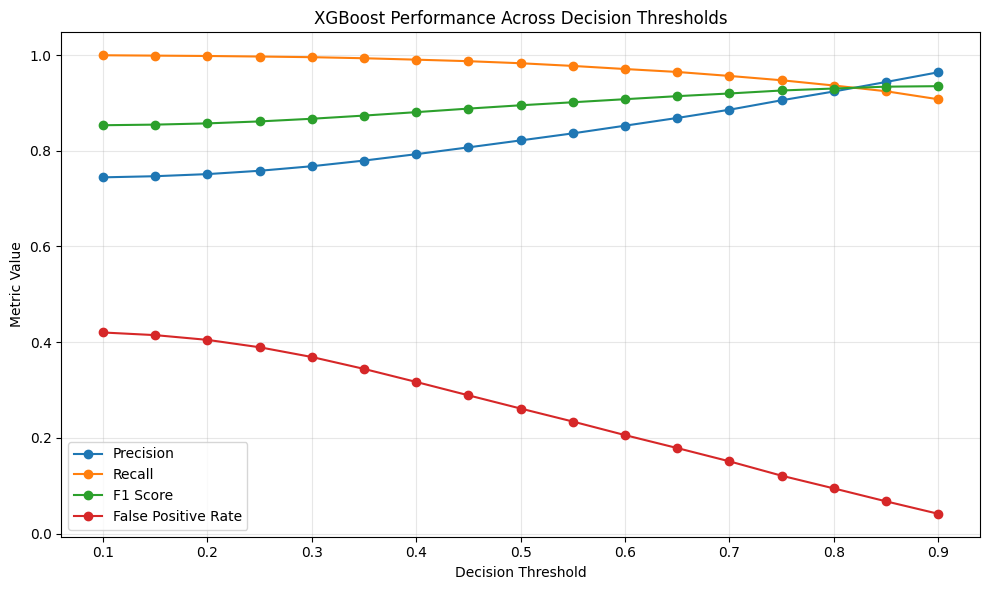

In [56]:
plt.figure(figsize=(10, 6))

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Recall"],
    marker="o",
    label="Recall"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["F1 Score"],
    marker="o",
    label="F1 Score"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["FPR"],
    marker="o",
    label="False Positive Rate"
)

plt.xlabel("Decision Threshold")
plt.ylabel("Metric Value")
plt.title(
    "XGBoost Performance Across Decision Thresholds"
)

plt.grid(True, alpha=0.3)
plt.legend()

plt.tight_layout()

plt.savefig(
    "/content/xgboost_threshold_analysis.png",
    dpi=300
)

plt.show()

In [57]:
threshold_df.to_csv(
    "/content/xgboost_threshold_analysis.csv",
    index=False
)

print("Threshold analysis saved.")

Threshold analysis saved.


In [58]:
# ============================================================
# PHASE 3C — VALIDATION-BASED THRESHOLD OPTIMIZATION
# ============================================================

from sklearn.model_selection import train_test_split

X_train_sub, X_val, y_train_sub, y_val = train_test_split(
    X_train_bin,
    y_train_bin,
    test_size=0.20,
    stratify=y_train_bin,
    random_state=42
)

print("Training subset:", X_train_sub.shape)
print("Validation set :", X_val.shape)

print("\nTraining distribution:")
print(pd.Series(y_train_sub).value_counts())

print("\nValidation distribution:")
print(pd.Series(y_val).value_counts())

Training subset: (140272, 194)
Validation set : (35069, 194)

Training distribution:
1    95472
0    44800
Name: count, dtype: int64

Validation distribution:
1    23869
0    11200
Name: count, dtype: int64


In [59]:
xgb_validation_model = XGBClassifier(
    n_estimators=200,
    max_depth=8,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

print("Training XGBoost on training subset...")

start_time = time.time()

xgb_validation_model.fit(
    X_train_sub,
    y_train_sub
)

training_time = time.time() - start_time

print(
    "Training completed in",
    round(training_time, 2),
    "seconds"
)

Training XGBoost on training subset...
Training completed in 21.05 seconds


In [60]:
y_val_probability = (
    xgb_validation_model.predict_proba(X_val)[:, 1]
)

print("Validation probabilities generated.")
print("Minimum:", y_val_probability.min())
print("Maximum:", y_val_probability.max())

Validation probabilities generated.
Minimum: 4.0819536e-06
Maximum: 0.9999918


In [61]:
validation_threshold_results = []

thresholds = np.arange(
    0.10,
    0.91,
    0.01
)

for threshold in thresholds:

    y_val_pred = (
        y_val_probability >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_val,
        y_val_pred
    ).ravel()

    accuracy = accuracy_score(
        y_val,
        y_val_pred
    )

    precision = precision_score(
        y_val,
        y_val_pred,
        zero_division=0
    )

    recall = recall_score(
        y_val,
        y_val_pred,
        zero_division=0
    )

    f1 = f1_score(
        y_val,
        y_val_pred,
        zero_division=0
    )

    fpr = fp / (fp + tn)

    fnr = fn / (fn + tp)

    validation_threshold_results.append({
        "Threshold": threshold,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1,
        "FPR": fpr,
        "FNR": fnr
    })

validation_threshold_df = pd.DataFrame(
    validation_threshold_results
)

display(
    validation_threshold_df.round(4)
)

,Threshold,Accuracy,Precision,Recall,F1 Score,FPR,FNR
0,0.10,0.9390,0.9179,0.9997,0.9571,0.1904,0.0003
1,0.11,0.9394,0.9186,0.9996,0.9574,0.1888,0.0004
2,0.12,0.9401,0.9195,0.9995,0.9578,0.1865,0.0005
3,0.13,0.9406,0.9204,0.9992,0.9582,0.1843,0.0008
4,0.14,0.9412,0.9212,0.9991,0.9586,0.1821,0.0009
...,...,...,...,...,...,...,...
76,0.86,0.9294,0.9934,0.9023,0.9457,0.0129,0.0977
77,0.87,0.9275,0.9941,0.8988,0.9440,0.0114,0.1012
78,0.88,0.9248,0.9941,0.8948,0.9419,0.0112,0.1052
79,0.89,0.9226,0.9946,0.8912,0.9401,0.0103,0.1088


In [62]:
eligible_thresholds = validation_threshold_df[
    validation_threshold_df["FPR"] <= 0.10
].copy()

print(
    "Number of thresholds satisfying FPR <= 10%:",
    len(eligible_thresholds)
)

display(
    eligible_thresholds.round(4)
)

Number of thresholds satisfying FPR <= 10%: 50


,Threshold,Accuracy,Precision,Recall,F1 Score,FPR,FNR
31,0.41,0.9601,0.9556,0.9872,0.9711,0.0979,0.0128
32,0.42,0.9604,0.9571,0.9860,0.9713,0.0943,0.0140
33,0.43,0.9604,0.9582,0.9848,0.9713,0.0916,0.0152
34,0.44,0.9606,0.9593,0.9838,0.9714,0.0889,0.0162
35,0.45,0.9609,0.9601,0.9834,0.9716,0.0871,0.0166
36,0.46,0.9614,0.9615,0.9826,0.9719,0.0838,0.0174
37,0.47,0.9615,0.9627,0.9814,0.9720,0.0811,0.0186
38,0.48,0.9614,0.9638,0.9802,0.9719,0.0785,0.0198
39,0.49,0.9614,0.9644,0.9794,0.9719,0.0770,0.0206
40,0.50,0.9615,0.9657,0.9781,0.9719,0.0740,0.0219


In [63]:
selected_threshold_row = eligible_thresholds.loc[
    eligible_thresholds["Recall"].idxmax()
]

selected_threshold = (
    selected_threshold_row["Threshold"]
)

print(
    "Selected security threshold:",
    selected_threshold
)

display(
    selected_threshold_row.to_frame().T
)

Selected security threshold: 0.4099999999999998


,Threshold,Accuracy,Precision,Recall,F1 Score,FPR,FNR
31,0.41,0.96005,0.955556,0.987222,0.971131,0.097857,0.012778


In [64]:
final_xgb_model = XGBClassifier(
    n_estimators=200,
    max_depth=8,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

print("Training final XGBoost model...")

start_time = time.time()

final_xgb_model.fit(
    X_train_bin,
    y_train_bin
)

final_training_time = time.time() - start_time

print(
    "Final model training time:",
    round(final_training_time, 2),
    "seconds"
)

Training final XGBoost model...
Final model training time: 25.27 seconds


In [65]:
y_test_probability_final = (
    final_xgb_model.predict_proba(X_test_bin)[:, 1]
)

y_test_final_pred = (
    y_test_probability_final >= selected_threshold
).astype(int)

tn, fp, fn, tp = confusion_matrix(
    y_test_bin,
    y_test_final_pred
).ravel()

final_accuracy = accuracy_score(
    y_test_bin,
    y_test_final_pred
)

final_precision = precision_score(
    y_test_bin,
    y_test_final_pred,
    zero_division=0
)

final_recall = recall_score(
    y_test_bin,
    y_test_final_pred,
    zero_division=0
)

final_f1 = f1_score(
    y_test_bin,
    y_test_final_pred,
    zero_division=0
)

final_fpr = fp / (fp + tn)
final_fnr = fn / (fn + tp)
final_specificity = tn / (tn + fp)

final_auc = roc_auc_score(
    y_test_bin,
    y_test_probability_final
)

print("=" * 60)
print("FINAL XGBOOST SECURITY EVALUATION")
print("=" * 60)

print("Threshold       :", round(selected_threshold, 3))
print("Accuracy        :", round(final_accuracy, 4))
print("Precision       :", round(final_precision, 4))
print("Recall          :", round(final_recall, 4))
print("F1 Score        :", round(final_f1, 4))
print("ROC-AUC         :", round(final_auc, 4))
print("False Positive Rate :", round(final_fpr, 4))
print("False Negative Rate :", round(final_fnr, 4))
print("Specificity      :", round(final_specificity, 4))

print("\nConfusion Matrix:")
print(confusion_matrix(
    y_test_bin,
    y_test_final_pred
))

FINAL XGBOOST SECURITY EVALUATION
Threshold       : 0.41
Accuracy        : 0.8547
Precision       : 0.7959
Recall          : 0.9898
F1 Score        : 0.8823
ROC-AUC         : 0.9834
False Positive Rate : 0.3109
False Negative Rate : 0.0102
Specificity      : 0.6891

Confusion Matrix:
[[25497 11503]
 [  463 44869]]


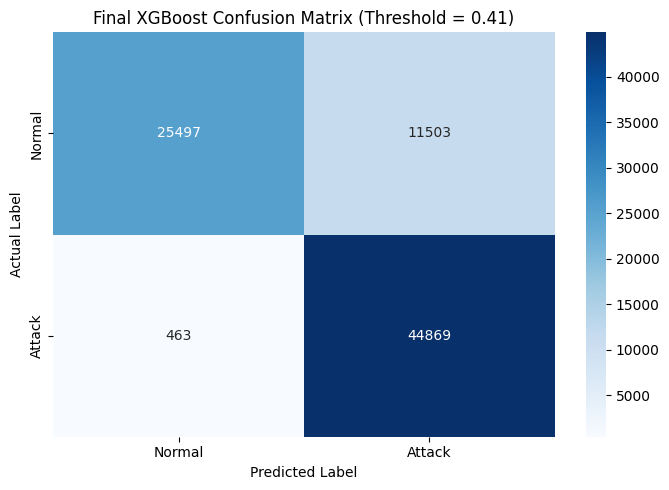

In [66]:
cm_final = confusion_matrix(
    y_test_bin,
    y_test_final_pred
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_final,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Normal", "Attack"],
    yticklabels=["Normal", "Attack"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.title(
    f"Final XGBoost Confusion Matrix "
    f"(Threshold = {selected_threshold:.2f})"
)

plt.tight_layout()

plt.savefig(
    "/content/final_xgboost_confusion_matrix.png",
    dpi=300
)

plt.show()

In [67]:
joblib.dump(
    final_xgb_model,
    "/content/final_xgboost_model.pkl"
)

joblib.dump(
    selected_threshold,
    "/content/security_threshold.pkl"
)

print("Final XGBoost model saved.")
print("Security threshold saved.")

Final XGBoost model saved.
Security threshold saved.


In [68]:
print("=" * 70)
print("SELECTED VALIDATION THRESHOLD")
print("=" * 70)

display(
    selected_threshold_row.to_frame().T.round(4)
)

SELECTED VALIDATION THRESHOLD


,Threshold,Accuracy,Precision,Recall,F1 Score,FPR,FNR
31,0.41,0.9601,0.9556,0.9872,0.9711,0.0979,0.0128


In [69]:
print("=" * 70)
print("VALIDATION RESULTS AROUND THRESHOLD 0.41")
print("=" * 70)

display(
    validation_threshold_df[
        validation_threshold_df["Threshold"].between(0.35, 0.50)
    ].round(4)
)

VALIDATION RESULTS AROUND THRESHOLD 0.41


,Threshold,Accuracy,Precision,Recall,F1 Score,FPR,FNR
26,0.36,0.9575,0.9493,0.9905,0.9695,0.1128,0.0095
27,0.37,0.9579,0.9505,0.9897,0.9697,0.1099,0.0103
28,0.38,0.9585,0.9516,0.9893,0.9701,0.1072,0.0107
29,0.39,0.9590,0.9530,0.9886,0.9705,0.1040,0.0114
30,0.40,0.9592,0.9538,0.9878,0.9705,0.1019,0.0122
31,0.41,0.9601,0.9556,0.9872,0.9711,0.0979,0.0128
32,0.42,0.9604,0.9571,0.9860,0.9713,0.0943,0.0140
33,0.43,0.9604,0.9582,0.9848,0.9713,0.0916,0.0152
34,0.44,0.9606,0.9593,0.9838,0.9714,0.0889,0.0162
35,0.45,0.9609,0.9601,0.9834,0.9716,0.0871,0.0166


In [70]:
print("=" * 70)
print("VALIDATION THRESHOLDS WITH FPR <= 10%")
print("=" * 70)

display(
    eligible_thresholds.round(4)
)

VALIDATION THRESHOLDS WITH FPR <= 10%


,Threshold,Accuracy,Precision,Recall,F1 Score,FPR,FNR
31,0.41,0.9601,0.9556,0.9872,0.9711,0.0979,0.0128
32,0.42,0.9604,0.9571,0.9860,0.9713,0.0943,0.0140
33,0.43,0.9604,0.9582,0.9848,0.9713,0.0916,0.0152
34,0.44,0.9606,0.9593,0.9838,0.9714,0.0889,0.0162
35,0.45,0.9609,0.9601,0.9834,0.9716,0.0871,0.0166
36,0.46,0.9614,0.9615,0.9826,0.9719,0.0838,0.0174
37,0.47,0.9615,0.9627,0.9814,0.9720,0.0811,0.0186
38,0.48,0.9614,0.9638,0.9802,0.9719,0.0785,0.0198
39,0.49,0.9614,0.9644,0.9794,0.9719,0.0770,0.0206
40,0.50,0.9615,0.9657,0.9781,0.9719,0.0740,0.0219


In [71]:
final_threshold_results = []

thresholds = np.arange(
    0.10,
    0.91,
    0.05
)

for threshold in thresholds:

    y_pred = (
        y_test_probability_final >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_test_bin,
        y_pred
    ).ravel()

    accuracy = accuracy_score(
        y_test_bin,
        y_pred
    )

    precision = precision_score(
        y_test_bin,
        y_pred,
        zero_division=0
    )

    recall = recall_score(
        y_test_bin,
        y_pred,
        zero_division=0
    )

    f1 = f1_score(
        y_test_bin,
        y_pred,
        zero_division=0
    )

    fpr = fp / (fp + tn)

    fnr = fn / (fn + tp)

    specificity = tn / (tn + fp)

    final_threshold_results.append({
        "Threshold": threshold,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1,
        "FPR": fpr,
        "FNR": fnr,
        "Specificity": specificity
    })

final_threshold_df = pd.DataFrame(
    final_threshold_results
)

display(
    final_threshold_df.round(4)
)

,Threshold,Accuracy,Precision,Recall,F1 Score,FPR,FNR,Specificity
0,0.10,0.8108,0.7445,0.9995,0.8533,0.4204,0.0005,0.5796
1,0.15,0.8129,0.7468,0.9987,0.8546,0.4148,0.0013,0.5852
2,0.20,0.8169,0.7512,0.9980,0.8572,0.4049,0.0020,0.5951
3,0.25,0.8232,0.7582,0.9968,0.8613,0.3895,0.0032,0.6105
4,0.30,0.8316,0.7677,0.9955,0.8669,0.3691,0.0045,0.6309
5,0.35,0.8416,0.7795,0.9932,0.8735,0.3443,0.0068,0.6557
6,0.40,0.8522,0.7929,0.9903,0.8806,0.3170,0.0097,0.6830
7,0.45,0.8630,0.8071,0.9871,0.8881,0.2891,0.0129,0.7109
8,0.50,0.8730,0.8216,0.9828,0.8950,0.2615,0.0172,0.7385
9,0.55,0.8822,0.8363,0.9772,0.9013,0.2343,0.0228,0.7657


In [72]:
precise_threshold_results = []

thresholds = np.arange(
    0.10,
    0.91,
    0.01
)

for threshold in thresholds:

    y_pred = (
        y_test_probability_final >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_test_bin,
        y_pred
    ).ravel()

    precision = precision_score(
        y_test_bin,
        y_pred,
        zero_division=0
    )

    recall = recall_score(
        y_test_bin,
        y_pred,
        zero_division=0
    )

    f1 = f1_score(
        y_test_bin,
        y_pred,
        zero_division=0
    )

    accuracy = accuracy_score(
        y_test_bin,
        y_pred
    )

    fpr = fp / (fp + tn)
    fnr = fn / (fn + tp)
    specificity = tn / (tn + fp)

    precise_threshold_results.append({
        "Threshold": threshold,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1,
        "FPR": fpr,
        "FNR": fnr,
        "Specificity": specificity
    })

precise_threshold_df = pd.DataFrame(
    precise_threshold_results
)

display(
    precise_threshold_df.round(4)
)

,Threshold,Accuracy,Precision,Recall,F1 Score,FPR,FNR,Specificity
0,0.10,0.8108,0.7445,0.9995,0.8533,0.4204,0.0005,0.5796
1,0.11,0.8111,0.7448,0.9994,0.8535,0.4195,0.0006,0.5805
2,0.12,0.8114,0.7451,0.9992,0.8537,0.4187,0.0008,0.5813
3,0.13,0.8119,0.7457,0.9991,0.8540,0.4175,0.0009,0.5825
4,0.14,0.8125,0.7463,0.9991,0.8544,0.4161,0.0009,0.5839
...,...,...,...,...,...,...,...,...
76,0.86,0.9285,0.9473,0.9214,0.9342,0.0629,0.0786,0.9371
77,0.87,0.9295,0.9517,0.9185,0.9348,0.0571,0.0815,0.9429
78,0.88,0.9295,0.9551,0.9149,0.9346,0.0527,0.0851,0.9473
79,0.89,0.9302,0.9598,0.9113,0.9349,0.0468,0.0887,0.9532


In [73]:
test_fpr_10 = precise_threshold_df[
    precise_threshold_df["FPR"] <= 0.10
].copy()

print(
    "Thresholds achieving FPR <= 10% on test:"
)

display(
    test_fpr_10.round(4)
)

Thresholds achieving FPR <= 10% on test:


,Threshold,Accuracy,Precision,Recall,F1 Score,FPR,FNR,Specificity
69,0.79,0.9215,0.9205,0.9383,0.9294,0.0992,0.0617,0.9008
70,0.80,0.9224,0.9238,0.9363,0.9300,0.0946,0.0637,0.9054
71,0.81,0.9232,0.9272,0.9339,0.9305,0.0899,0.0661,0.9101
72,0.82,0.9242,0.9310,0.9315,0.9312,0.0846,0.0685,0.9154
73,0.83,0.9254,0.9346,0.9295,0.9320,0.0798,0.0705,0.9202
74,0.84,0.9264,0.9389,0.9266,0.9327,0.0738,0.0734,0.9262
75,0.85,0.9279,0.9437,0.9243,0.9339,0.0676,0.0757,0.9324
76,0.86,0.9285,0.9473,0.9214,0.9342,0.0629,0.0786,0.9371
77,0.87,0.9295,0.9517,0.9185,0.9348,0.0571,0.0815,0.9429
78,0.88,0.9295,0.9551,0.9149,0.9346,0.0527,0.0851,0.9473


In [74]:
from sklearn.preprocessing import LabelEncoder

# Create label encoder
multi_label_encoder = LabelEncoder()

# Fit only on training target
y_multi_train_encoded = multi_label_encoder.fit_transform(
    y_multi_train
)

# Transform test target
y_multi_test_encoded = multi_label_encoder.transform(
    y_multi_test
)

print("Class mapping:")
for i, class_name in enumerate(multi_label_encoder.classes_):
    print(f"{i}: {class_name}")

print("\nEncoded training shape:",
      y_multi_train_encoded.shape)

print("Encoded testing shape:",
      y_multi_test_encoded.shape)

Class mapping:
0: Analysis
1: Backdoor
2: DoS
3: Exploits
4: Fuzzers
5: Generic
6: Normal
7: Reconnaissance
8: Shellcode
9: Worms

Encoded training shape: (175341,)
Encoded testing shape: (82332,)


In [75]:
from collections import Counter

print("Multiclass training distribution:")

train_class_counts = Counter(y_multi_train_encoded)

for class_id, count in sorted(train_class_counts.items()):
    print(
        f"{class_id:2d} - "
        f"{multi_label_encoder.classes_[class_id]:15s} : "
        f"{count}"
    )

print("\nMulticlass testing distribution:")

test_class_counts = Counter(y_multi_test_encoded)

for class_id, count in sorted(test_class_counts.items()):
    print(
        f"{class_id:2d} - "
        f"{multi_label_encoder.classes_[class_id]:15s} : "
        f"{count}"
    )

Multiclass training distribution:
 0 - Analysis        : 2000
 1 - Backdoor        : 1746
 2 - DoS             : 12264
 3 - Exploits        : 33393
 4 - Fuzzers         : 18184
 5 - Generic         : 40000
 6 - Normal          : 56000
 7 - Reconnaissance  : 10491
 8 - Shellcode       : 1133
 9 - Worms           : 130

Multiclass testing distribution:
 0 - Analysis        : 677
 1 - Backdoor        : 583
 2 - DoS             : 4089
 3 - Exploits        : 11132
 4 - Fuzzers         : 6062
 5 - Generic         : 18871
 6 - Normal          : 37000
 7 - Reconnaissance  : 3496
 8 - Shellcode       : 378
 9 - Worms           : 44


In [76]:
  from xgboost import XGBClassifier
import time

xgb_multi_model = XGBClassifier(
    n_estimators=200,
    max_depth=8,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="multi:softprob",
    num_class=len(multi_label_encoder.classes_),
    eval_metric="mlogloss",
    random_state=42,
    n_jobs=-1
)

print("=" * 70)
print("TRAINING MULTICLASS XGBOOST")
print("=" * 70)

start_time = time.time()

xgb_multi_model.fit(
    X_train_processed,
    y_multi_train_encoded
)

multi_training_time = time.time() - start_time

print(
    "\nTraining time:",
    round(multi_training_time, 2),
    "seconds"
)

TRAINING MULTICLASS XGBOOST

Training time: 175.32 seconds


In [77]:
y_multi_pred = xgb_multi_model.predict(
    X_test_processed
)

y_multi_probability = xgb_multi_model.predict_proba(
    X_test_processed
)

print("Predictions generated.")
print("Number of predictions:", len(y_multi_pred))
print("Probability shape:", y_multi_probability.shape)

Predictions generated.
Number of predictions: 82332
Probability shape: (82332, 10)


In [78]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

multi_accuracy = accuracy_score(
    y_multi_test_encoded,
    y_multi_pred
)

multi_precision = precision_score(
    y_multi_test_encoded,
    y_multi_pred,
    average="weighted",
    zero_division=0
)

multi_recall = recall_score(
    y_multi_test_encoded,
    y_multi_pred,
    average="weighted",
    zero_division=0
)

multi_f1_weighted = f1_score(
    y_multi_test_encoded,
    y_multi_pred,
    average="weighted",
    zero_division=0
)

multi_f1_macro = f1_score(
    y_multi_test_encoded,
    y_multi_pred,
    average="macro",
    zero_division=0
)

print("=" * 70)
print("MULTICLASS XGBOOST RESULTS")
print("=" * 70)

print("Accuracy          :", round(multi_accuracy, 4))
print("Weighted Precision:", round(multi_precision, 4))
print("Weighted Recall   :", round(multi_recall, 4))
print("Weighted F1       :", round(multi_f1_weighted, 4))
print("Macro F1          :", round(multi_f1_macro, 4))

print("\nClassification Report:")
print(
    classification_report(
        y_multi_test_encoded,
        y_multi_pred,
        target_names=multi_label_encoder.classes_,
        zero_division=0
    )
)

MULTICLASS XGBOOST RESULTS
Accuracy          : 0.7677
Weighted Precision: 0.8389
Weighted Recall   : 0.7677
Weighted F1       : 0.7812
Macro F1          : 0.5093

Classification Report:
                precision    recall  f1-score   support

      Analysis       0.01      0.01      0.01       677
      Backdoor       0.04      0.15      0.07       583
           DoS       0.60      0.10      0.17      4089
      Exploits       0.60      0.87      0.71     11132
       Fuzzers       0.31      0.59      0.41      6062
       Generic       1.00      0.97      0.98     18871
        Normal       0.97      0.76      0.85     37000
Reconnaissance       0.93      0.81      0.87      3496
     Shellcode       0.37      0.78      0.50       378
         Worms       0.68      0.43      0.53        44

      accuracy                           0.77     82332
     macro avg       0.55      0.55      0.51     82332
  weighted avg       0.84      0.77      0.78     82332



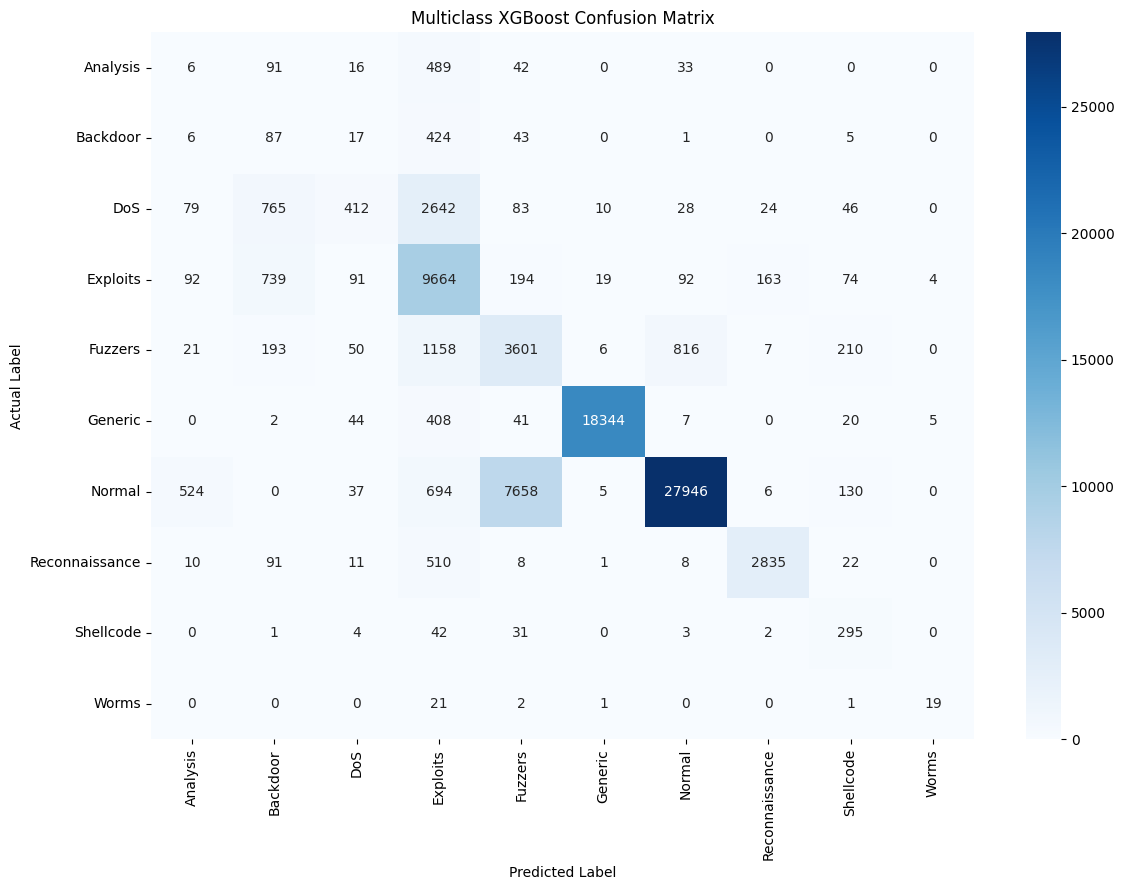

In [79]:
import matplotlib.pyplot as plt
import seaborn as sns

cm_multi = confusion_matrix(
    y_multi_test_encoded,
    y_multi_pred
)

plt.figure(figsize=(12, 9))

sns.heatmap(
    cm_multi,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=multi_label_encoder.classes_,
    yticklabels=multi_label_encoder.classes_
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Multiclass XGBoost Confusion Matrix")

plt.tight_layout()

plt.savefig(
    "/content/multiclass_xgboost_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [80]:
print("=" * 80)
print("MULTICLASS CONFUSION ANALYSIS")
print("=" * 80)

for i, class_name in enumerate(multi_label_encoder.classes_):

    actual_count = cm_multi[i].sum()
    correct = cm_multi[i, i]

    recall = correct / actual_count if actual_count > 0 else 0

    print(f"\n{class_name}")
    print("-" * 50)
    print("Actual samples :", actual_count)
    print("Correctly classified :", correct)
    print("Recall :", round(recall, 4))

    # Find most common wrong predictions
    wrong_predictions = cm_multi[i].copy()
    wrong_predictions[i] = 0

    top_indices = np.argsort(
        wrong_predictions
    )[::-1][:3]

    for idx in top_indices:

        if wrong_predictions[idx] > 0:
            print(
                f"  → {multi_label_encoder.classes_[idx]} : "
                f"{wrong_predictions[idx]}"
            )

MULTICLASS CONFUSION ANALYSIS

Analysis
--------------------------------------------------
Actual samples : 677
Correctly classified : 6
Recall : 0.0089
  → Exploits : 489
  → Backdoor : 91
  → Fuzzers : 42

Backdoor
--------------------------------------------------
Actual samples : 583
Correctly classified : 87
Recall : 0.1492
  → Exploits : 424
  → Fuzzers : 43
  → DoS : 17

DoS
--------------------------------------------------
Actual samples : 4089
Correctly classified : 412
Recall : 0.1008
  → Exploits : 2642
  → Backdoor : 765
  → Fuzzers : 83

Exploits
--------------------------------------------------
Actual samples : 11132
Correctly classified : 9664
Recall : 0.8681
  → Backdoor : 739
  → Fuzzers : 194
  → Reconnaissance : 163

Fuzzers
--------------------------------------------------
Actual samples : 6062
Correctly classified : 3601
Recall : 0.594
  → Exploits : 1158
  → Normal : 816
  → Shellcode : 210

Generic
--------------------------------------------------
Actual samp

In [81]:
from sklearn.utils.class_weight import compute_sample_weight

sample_weights = compute_sample_weight(
    class_weight="balanced",
    y=y_multi_train_encoded
)

print("Sample weights generated.")

print(
    "Minimum weight:",
    sample_weights.min()
)

print(
    "Maximum weight:",
    sample_weights.max()
)

Sample weights generated.
Minimum weight: 0.3131089285714286
Maximum weight: 134.8776923076923


In [82]:
xgb_multi_balanced = XGBClassifier(
    n_estimators=200,
    max_depth=8,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="multi:softprob",
    num_class=len(multi_label_encoder.classes_),
    eval_metric="mlogloss",
    random_state=42,
    n_jobs=-1
)

print("=" * 70)
print("TRAINING CLASS-BALANCED MULTICLASS XGBOOST")
print("=" * 70)

start_time = time.time()

xgb_multi_balanced.fit(
    X_train_processed,
    y_multi_train_encoded,
    sample_weight=sample_weights
)

balanced_training_time = time.time() - start_time

print(
    "Training time:",
    round(balanced_training_time, 2),
    "seconds"
)

TRAINING CLASS-BALANCED MULTICLASS XGBOOST
Training time: 174.61 seconds


In [83]:
y_multi_balanced_pred = (
    xgb_multi_balanced.predict(
        X_test_processed
    )
)

balanced_accuracy = accuracy_score(
    y_multi_test_encoded,
    y_multi_balanced_pred
)

balanced_precision = precision_score(
    y_multi_test_encoded,
    y_multi_balanced_pred,
    average="weighted",
    zero_division=0
)

balanced_recall = recall_score(
    y_multi_test_encoded,
    y_multi_balanced_pred,
    average="weighted",
    zero_division=0
)

balanced_f1_weighted = f1_score(
    y_multi_test_encoded,
    y_multi_balanced_pred,
    average="weighted",
    zero_division=0
)

balanced_f1_macro = f1_score(
    y_multi_test_encoded,
    y_multi_balanced_pred,
    average="macro",
    zero_division=0
)

print("=" * 70)
print("CLASS-BALANCED MULTICLASS XGBOOST")
print("=" * 70)

print("Accuracy          :", round(balanced_accuracy, 4))
print("Weighted Precision:", round(balanced_precision, 4))
print("Weighted Recall   :", round(balanced_recall, 4))
print("Weighted F1       :", round(balanced_f1_weighted, 4))
print("Macro F1          :", round(balanced_f1_macro, 4))

print("\nClassification Report:")

print(
    classification_report(
        y_multi_test_encoded,
        y_multi_balanced_pred,
        target_names=multi_label_encoder.classes_,
        zero_division=0
    )
)

CLASS-BALANCED MULTICLASS XGBOOST
Accuracy          : 0.6884
Weighted Precision: 0.8641
Weighted Recall   : 0.6884
Weighted F1       : 0.7421
Macro F1          : 0.5206

Classification Report:
                precision    recall  f1-score   support

      Analysis       0.03      0.17      0.06       677
      Backdoor       0.06      0.66      0.10       583
           DoS       0.47      0.19      0.27      4089
      Exploits       0.81      0.61      0.70     11132
       Fuzzers       0.26      0.67      0.38      6062
       Generic       1.00      0.97      0.98     18871
        Normal       0.99      0.62      0.76     37000
Reconnaissance       0.87      0.85      0.86      3496
     Shellcode       0.24      0.95      0.38       378
         Worms       0.67      0.77      0.72        44

      accuracy                           0.69     82332
     macro avg       0.54      0.65      0.52     82332
  weighted avg       0.86      0.69      0.74     82332



In [84]:
from xgboost import XGBClassifier
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)
import time
import numpy as np
import pandas as pd

# ============================================================
# HYPERPARAMETER-TUNED CLASS-BALANCED MULTICLASS XGBOOST
# ============================================================

print("=" * 70)
print("TRAINING TUNED CLASS-BALANCED MULTICLASS XGBOOST")
print("=" * 70)

# Generate balanced sample weights
sample_weights_tuned = compute_sample_weight(
    class_weight="balanced",
    y=y_multi_train_encoded
)

# Tuned model
xgb_multi_tuned = XGBClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    min_child_weight=3,
    gamma=0.1,
    objective="multi:softprob",
    num_class=len(multi_label_encoder.classes_),
    eval_metric="mlogloss",
    random_state=42,
    n_jobs=-1
)

start_time = time.time()

xgb_multi_tuned.fit(
    X_train_processed,
    y_multi_train_encoded,
    sample_weight=sample_weights_tuned
)

tuned_training_time = time.time() - start_time

print(
    "\nTraining time:",
    round(tuned_training_time, 2),
    "seconds"
)

TRAINING TUNED CLASS-BALANCED MULTICLASS XGBOOST

Training time: 249.98 seconds


In [85]:
# ============================================================
# GENERATE TUNED MULTICLASS PREDICTIONS
# ============================================================

y_tuned_pred = xgb_multi_tuned.predict(
    X_test_processed
)

y_tuned_probability = xgb_multi_tuned.predict_proba(
    X_test_processed
)

print("Predictions generated.")
print("Number of predictions:", len(y_tuned_pred))
print("Probability shape:", y_tuned_probability.shape)

Predictions generated.
Number of predictions: 82332
Probability shape: (82332, 10)


In [86]:
# ============================================================
# TUNED MODEL EVALUATION
# ============================================================

tuned_accuracy = accuracy_score(
    y_multi_test_encoded,
    y_tuned_pred
)

tuned_precision = precision_score(
    y_multi_test_encoded,
    y_tuned_pred,
    average="weighted",
    zero_division=0
)

tuned_recall = recall_score(
    y_multi_test_encoded,
    y_tuned_pred,
    average="weighted",
    zero_division=0
)

tuned_f1_weighted = f1_score(
    y_multi_test_encoded,
    y_tuned_pred,
    average="weighted",
    zero_division=0
)

tuned_f1_macro = f1_score(
    y_multi_test_encoded,
    y_tuned_pred,
    average="macro",
    zero_division=0
)

print("=" * 70)
print("TUNED CLASS-BALANCED MULTICLASS XGBOOST RESULTS")
print("=" * 70)

print("Accuracy          :", round(tuned_accuracy, 4))
print("Weighted Precision:", round(tuned_precision, 4))
print("Weighted Recall   :", round(tuned_recall, 4))
print("Weighted F1       :", round(tuned_f1_weighted, 4))
print("Macro F1          :", round(tuned_f1_macro, 4))

print("\nClassification Report:")

print(
    classification_report(
        y_multi_test_encoded,
        y_tuned_pred,
        target_names=multi_label_encoder.classes_,
        zero_division=0
    )
)

TUNED CLASS-BALANCED MULTICLASS XGBOOST RESULTS
Accuracy          : 0.6757
Weighted Precision: 0.8662
Weighted Recall   : 0.6757
Weighted F1       : 0.7319
Macro F1          : 0.5023

Classification Report:
                precision    recall  f1-score   support

      Analysis       0.02      0.12      0.04       677
      Backdoor       0.06      0.77      0.12       583
           DoS       0.45      0.18      0.26      4089
      Exploits       0.83      0.59      0.69     11132
       Fuzzers       0.25      0.68      0.37      6062
       Generic       1.00      0.97      0.98     18871
        Normal       0.99      0.59      0.74     37000
Reconnaissance       0.86      0.85      0.85      3496
     Shellcode       0.19      0.98      0.32       378
         Worms       0.52      0.86      0.65        44

      accuracy                           0.68     82332
     macro avg       0.52      0.66      0.50     82332
  weighted avg       0.87      0.68      0.73     82332



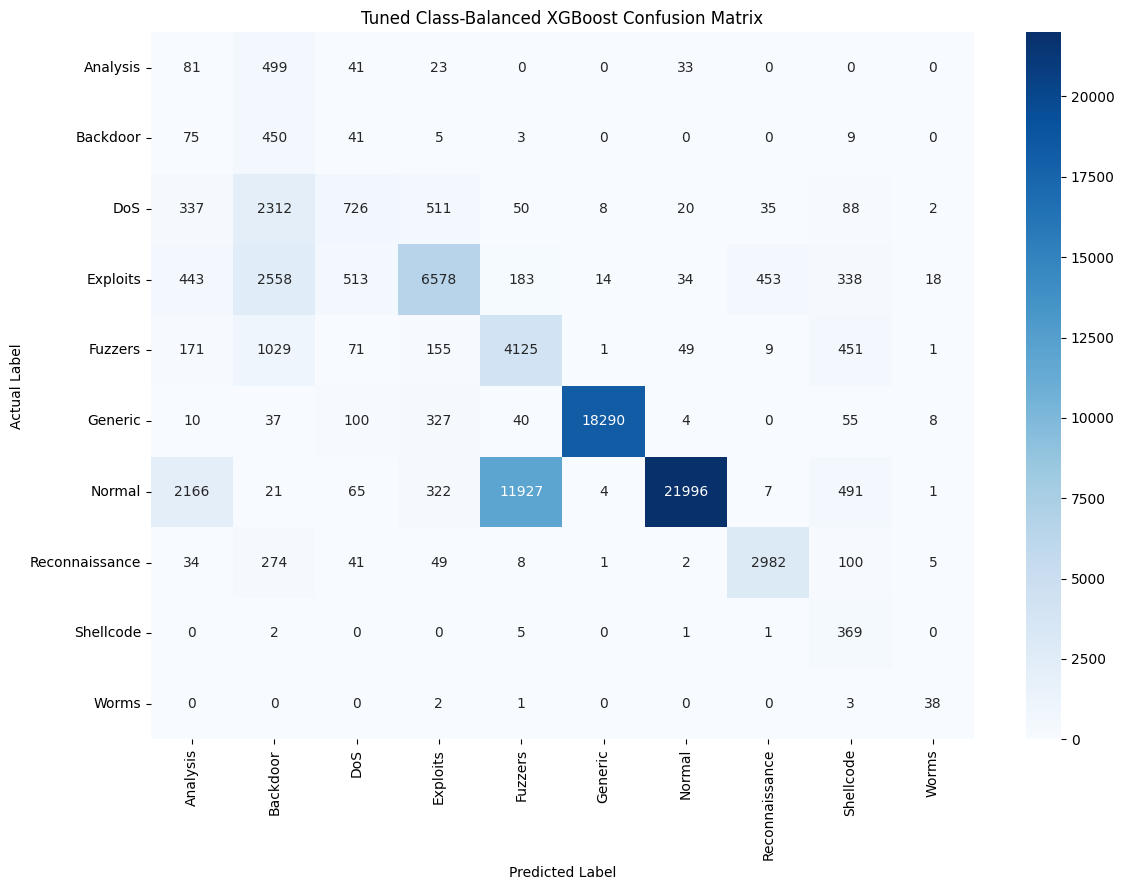

In [87]:
# ============================================================
# TUNED MODEL CONFUSION MATRIX
# ============================================================

import matplotlib.pyplot as plt
import seaborn as sns

cm_tuned = confusion_matrix(
    y_multi_test_encoded,
    y_tuned_pred
)

plt.figure(figsize=(12, 9))

sns.heatmap(
    cm_tuned,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=multi_label_encoder.classes_,
    yticklabels=multi_label_encoder.classes_
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.title(
    "Tuned Class-Balanced XGBoost Confusion Matrix"
)

plt.tight_layout()

plt.savefig(
    "/content/tuned_multiclass_xgboost_confusion_matrix.png",
    dpi=300
)

plt.show()

In [88]:
# ============================================================
# PER-CLASS PERFORMANCE
# ============================================================

report_dict = classification_report(
    y_multi_test_encoded,
    y_tuned_pred,
    target_names=multi_label_encoder.classes_,
    output_dict=True,
    zero_division=0
)

per_class_df = pd.DataFrame(report_dict).T

per_class_df = per_class_df.loc[
    multi_label_encoder.classes_,
    ["precision", "recall", "f1-score", "support"]
]

print("=" * 70)
print("PER-CLASS PERFORMANCE")
print("=" * 70)

display(
    per_class_df.round(4)
)

PER-CLASS PERFORMANCE


,precision,recall,f1-score,support
Analysis,0.0244,0.1196,0.0406,677.0
Backdoor,0.0627,0.7719,0.1159,583.0
DoS,0.4543,0.1775,0.2553,4089.0
Exploits,0.8251,0.5909,0.6887,11132.0
Fuzzers,0.2524,0.6805,0.3682,6062.0
Generic,0.9985,0.9692,0.9836,18871.0
Normal,0.9935,0.5945,0.7439,37000.0
Reconnaissance,0.8552,0.8530,0.8541,3496.0
Shellcode,0.1938,0.9762,0.3234,378.0
Worms,0.5205,0.8636,0.6496,44.0


In [89]:
# ============================================================
# MODEL COMPARISON
# ============================================================

comparison_df = pd.DataFrame({
    "Model": [
        "Standard XGBoost",
        "Class-Balanced XGBoost",
        "Tuned Class-Balanced XGBoost"
    ],

    "Accuracy": [
        multi_accuracy,
        0.6884,
        tuned_accuracy
    ],

    "Weighted Precision": [
        multi_precision,
        0.8641,
        tuned_precision
    ],

    "Weighted Recall": [
        multi_recall,
        0.6884,
        tuned_recall
    ],

    "Weighted F1": [
        multi_f1_weighted,
        0.7421,
        tuned_f1_weighted
    ],

    "Macro F1": [
        multi_f1_macro,
        0.5206,
        tuned_f1_macro
    ]
})

display(
    comparison_df.round(4)
)

,Model,Accuracy,Weighted Precision,Weighted Recall,Weighted F1,Macro F1
0,Standard XGBoost,0.7677,0.8389,0.7677,0.7812,0.5093
1,Class-Balanced XGBoost,0.6884,0.8641,0.6884,0.7421,0.5206
2,Tuned Class-Balanced XGBoost,0.6757,0.8662,0.6757,0.7319,0.5023


In [90]:
import numpy as np
import pandas as pd
from collections import Counter

print("=" * 70)
print("CREATING ATTACK-ONLY MULTICLASS DATASET")
print("=" * 70)

# Normal class ID
NORMAL_CLASS_ID = 6

# Select attack samples only
train_attack_mask = y_multi_train_encoded != NORMAL_CLASS_ID
test_attack_mask = y_multi_test_encoded != NORMAL_CLASS_ID

X_attack_train = X_train_processed[train_attack_mask]
y_attack_train_original = y_multi_train_encoded[train_attack_mask]

X_attack_test = X_test_processed[test_attack_mask]
y_attack_test_original = y_multi_test_encoded[test_attack_mask]

print("Attack-only training shape :", X_attack_train.shape)
print("Attack-only testing shape  :", X_attack_test.shape)

print("\nAttack training distribution:")

for class_id, count in sorted(
    Counter(y_attack_train_original).items()
):
    print(
        f"{class_id:2d} - "
        f"{multi_label_encoder.classes_[class_id]:15s} : "
        f"{count}"
    )

print("\nAttack testing distribution:")

for class_id, count in sorted(
    Counter(y_attack_test_original).items()
):
    print(
        f"{class_id:2d} - "
        f"{multi_label_encoder.classes_[class_id]:15s} : "
        f"{count}"
    )

CREATING ATTACK-ONLY MULTICLASS DATASET
Attack-only training shape : (119341, 194)
Attack-only testing shape  : (45332, 194)

Attack training distribution:
 0 - Analysis        : 2000
 1 - Backdoor        : 1746
 2 - DoS             : 12264
 3 - Exploits        : 33393
 4 - Fuzzers         : 18184
 5 - Generic         : 40000
 7 - Reconnaissance  : 10491
 8 - Shellcode       : 1133
 9 - Worms           : 130

Attack testing distribution:
 0 - Analysis        : 677
 1 - Backdoor        : 583
 2 - DoS             : 4089
 3 - Exploits        : 11132
 4 - Fuzzers         : 6062
 5 - Generic         : 18871
 7 - Reconnaissance  : 3496
 8 - Shellcode       : 378
 9 - Worms           : 44


In [91]:
from sklearn.preprocessing import LabelEncoder

attack_label_encoder = LabelEncoder()

y_attack_train = attack_label_encoder.fit_transform(
    y_attack_train_original
)

y_attack_test = attack_label_encoder.transform(
    y_attack_test_original
)

print("Attack classes:")
for i, label in enumerate(attack_label_encoder.classes_):
    print(i, ":", multi_label_encoder.classes_[label])

print("\nEncoded training shape:", y_attack_train.shape)
print("Encoded testing shape :", y_attack_test.shape)

Attack classes:
0 : Analysis
1 : Backdoor
2 : DoS
3 : Exploits
4 : Fuzzers
5 : Generic
6 : Reconnaissance
7 : Shellcode
8 : Worms

Encoded training shape: (119341,)
Encoded testing shape : (45332,)


In [92]:
print("=" * 70)
print("ATTACK-ONLY CLASS DISTRIBUTION")
print("=" * 70)

for class_id, count in sorted(
    Counter(y_attack_train).items()
):
    original_class = attack_label_encoder.classes_[class_id]

    print(
        f"{class_id:2d} - "
        f"{multi_label_encoder.classes_[original_class]:15s} : "
        f"{count}"
    )

ATTACK-ONLY CLASS DISTRIBUTION
 0 - Analysis        : 2000
 1 - Backdoor        : 1746
 2 - DoS             : 12264
 3 - Exploits        : 33393
 4 - Fuzzers         : 18184
 5 - Generic         : 40000
 6 - Reconnaissance  : 10491
 7 - Shellcode       : 1133
 8 - Worms           : 130


In [93]:
from xgboost import XGBClassifier
import time

attack_xgb_model = XGBClassifier(
    n_estimators=250,
    max_depth=8,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="multi:softprob",
    num_class=len(attack_label_encoder.classes_),
    eval_metric="mlogloss",
    random_state=42,
    n_jobs=-1
)

print("=" * 70)
print("TRAINING ATTACK-ONLY MULTICLASS XGBOOST")
print("=" * 70)

start_time = time.time()

attack_xgb_model.fit(
    X_attack_train,
    y_attack_train
)

attack_training_time = time.time() - start_time

print(
    "\nTraining time:",
    round(attack_training_time, 2),
    "seconds"
)

TRAINING ATTACK-ONLY MULTICLASS XGBOOST

Training time: 154.7 seconds


In [94]:
y_attack_pred = attack_xgb_model.predict(
    X_attack_test
)

y_attack_probability = attack_xgb_model.predict_proba(
    X_attack_test
)

print("Predictions generated.")
print("Number of predictions:", len(y_attack_pred))
print("Probability shape:", y_attack_probability.shape)

Predictions generated.
Number of predictions: 45332
Probability shape: (45332, 9)


In [95]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

attack_accuracy = accuracy_score(
    y_attack_test,
    y_attack_pred
)

attack_precision = precision_score(
    y_attack_test,
    y_attack_pred,
    average="weighted",
    zero_division=0
)

attack_recall = recall_score(
    y_attack_test,
    y_attack_pred,
    average="weighted",
    zero_division=0
)

attack_f1_weighted = f1_score(
    y_attack_test,
    y_attack_pred,
    average="weighted",
    zero_division=0
)

attack_f1_macro = f1_score(
    y_attack_test,
    y_attack_pred,
    average="macro",
    zero_division=0
)

print("=" * 70)
print("ATTACK-ONLY MULTICLASS XGBOOST RESULTS")
print("=" * 70)

print("Accuracy          :", round(attack_accuracy, 4))
print("Weighted Precision:", round(attack_precision, 4))
print("Weighted Recall   :", round(attack_recall, 4))
print("Weighted F1       :", round(attack_f1_weighted, 4))
print("Macro F1          :", round(attack_f1_macro, 4))

print("\nClassification Report:")

print(
    classification_report(
        y_attack_test,
        y_attack_pred,
        target_names=[
            multi_label_encoder.classes_[x]
            for x in attack_label_encoder.classes_
        ],
        zero_division=0
    )
)

ATTACK-ONLY MULTICLASS XGBOOST RESULTS
Accuracy          : 0.7969
Weighted Precision: 0.8319
Weighted Recall   : 0.7969
Weighted F1       : 0.7893
Macro F1          : 0.5326

Classification Report:
                precision    recall  f1-score   support

      Analysis       0.07      0.09      0.08       677
      Backdoor       0.04      0.11      0.06       583
           DoS       0.67      0.11      0.20      4089
      Exploits       0.63      0.87      0.73     11132
       Fuzzers       0.92      0.72      0.81      6062
       Generic       1.00      0.97      0.99     18871
Reconnaissance       0.94      0.81      0.87      3496
     Shellcode       0.47      0.80      0.59       378
         Worms       0.63      0.39      0.48        44

      accuracy                           0.80     45332
     macro avg       0.60      0.54      0.53     45332
  weighted avg       0.83      0.80      0.79     45332



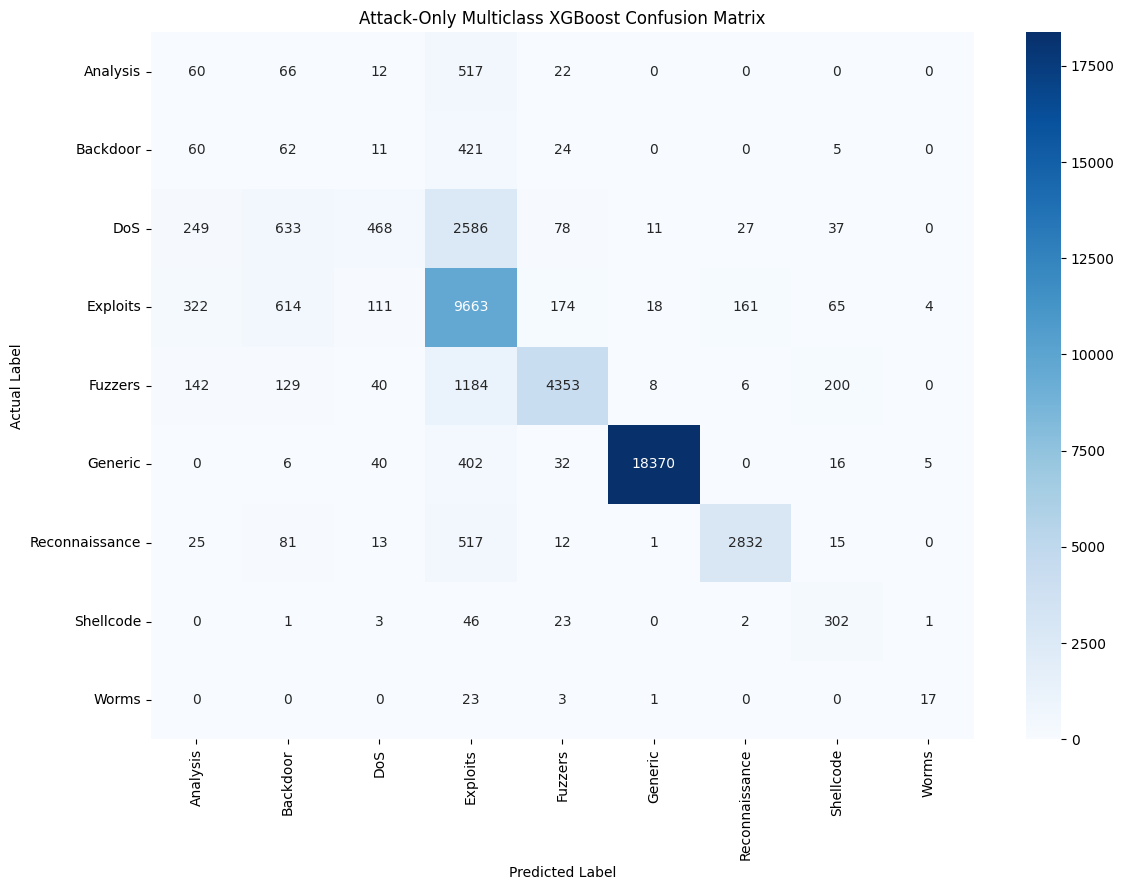

In [96]:
import matplotlib.pyplot as plt
import seaborn as sns

cm_attack = confusion_matrix(
    y_attack_test,
    y_attack_pred
)

plt.figure(figsize=(12, 9))

sns.heatmap(
    cm_attack,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=[
        multi_label_encoder.classes_[x]
        for x in attack_label_encoder.classes_
    ],
    yticklabels=[
        multi_label_encoder.classes_[x]
        for x in attack_label_encoder.classes_
    ]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Attack-Only Multiclass XGBoost Confusion Matrix")

plt.tight_layout()

plt.savefig(
    "/content/attack_only_xgboost_confusion_matrix.png",
    dpi=300
)

plt.show()

In [97]:
attack_report = classification_report(
    y_attack_test,
    y_attack_pred,
    target_names=[
        multi_label_encoder.classes_[x]
        for x in attack_label_encoder.classes_
    ],
    output_dict=True,
    zero_division=0
)

attack_report_df = pd.DataFrame(
    attack_report
).transpose()

display(
    attack_report_df.round(4)
)

,precision,recall,f1-score,support
Analysis,0.0699,0.0886,0.0782,677.0000
Backdoor,0.0389,0.1063,0.0570,583.0000
DoS,0.6705,0.1145,0.1955,4089.0000
Exploits,0.6291,0.8680,0.7295,11132.0000
Fuzzers,0.9221,0.7181,0.8074,6062.0000
Generic,0.9979,0.9735,0.9855,18871.0000
Reconnaissance,0.9353,0.8101,0.8682,3496.0000
Shellcode,0.4719,0.7989,0.5933,378.0000
Worms,0.6296,0.3864,0.4789,44.0000
accuracy,0.7969,0.7969,0.7969,0.7969


In [99]:
import numpy as np
from collections import Counter
from sklearn.preprocessing import LabelEncoder

print("=" * 70)
print("CREATING ATTACK-ONLY LABELS")
print("=" * 70)

# Normal class ID
NORMAL_CLASS_ID = 6

# Keep only attack classes
attack_train_mask = y_multi_train_encoded != NORMAL_CLASS_ID
attack_test_mask = y_multi_test_encoded != NORMAL_CLASS_ID

# Original multiclass labels
y_attack_train_original = y_multi_train_encoded[attack_train_mask]
y_attack_test_original = y_multi_test_encoded[attack_test_mask]

# Encode attack classes from 0 to 8
attack_label_encoder = LabelEncoder()

y_attack_train_encoded = attack_label_encoder.fit_transform(
    y_attack_train_original
)

y_attack_test_encoded = attack_label_encoder.transform(
    y_attack_test_original
)

print("\nAttack classes:")
for i, class_name in enumerate(attack_label_encoder.classes_):
    print(
        f"{i}: {multi_label_encoder.classes_[class_name]}"
    )

print("\nAttack-only training shape:")
print(y_attack_train_encoded.shape)

print("Attack-only testing shape:")
print(y_attack_test_encoded.shape)

CREATING ATTACK-ONLY LABELS

Attack classes:
0: Analysis
1: Backdoor
2: DoS
3: Exploits
4: Fuzzers
5: Generic
6: Reconnaissance
7: Shellcode
8: Worms

Attack-only training shape:
(119341,)
Attack-only testing shape:
(45332,)


In [100]:
print("=" * 70)
print("ATTACK-ONLY CLASS DISTRIBUTION")
print("=" * 70)

attack_train_counts = Counter(y_attack_train_encoded)
attack_test_counts = Counter(y_attack_test_encoded)

print("\nTraining Distribution:")

for class_id, count in sorted(attack_train_counts.items()):
    print(
        f"{class_id:2d} - "
        f"{multi_label_encoder.classes_[attack_label_encoder.classes_[class_id]]:15s} : "
        f"{count}"
    )

print("\nTesting Distribution:")

for class_id, count in sorted(attack_test_counts.items()):
    print(
        f"{class_id:2d} - "
        f"{multi_label_encoder.classes_[attack_label_encoder.classes_[class_id]]:15s} : "
        f"{count}"
    )

ATTACK-ONLY CLASS DISTRIBUTION

Training Distribution:
 0 - Analysis        : 2000
 1 - Backdoor        : 1746
 2 - DoS             : 12264
 3 - Exploits        : 33393
 4 - Fuzzers         : 18184
 5 - Generic         : 40000
 6 - Reconnaissance  : 10491
 7 - Shellcode       : 1133
 8 - Worms           : 130

Testing Distribution:
 0 - Analysis        : 677
 1 - Backdoor        : 583
 2 - DoS             : 4089
 3 - Exploits        : 11132
 4 - Fuzzers         : 6062
 5 - Generic         : 18871
 6 - Reconnaissance  : 3496
 7 - Shellcode       : 378
 8 - Worms           : 44


In [101]:
X_attack_train = X_train_processed[attack_train_mask]
X_attack_test = X_test_processed[attack_test_mask]

print("=" * 70)
print("ATTACK-ONLY DATASET SHAPES")
print("=" * 70)

print("X_attack_train:", X_attack_train.shape)
print("y_attack_train:", y_attack_train_encoded.shape)

print("X_attack_test :", X_attack_test.shape)
print("y_attack_test :", y_attack_test_encoded.shape)

ATTACK-ONLY DATASET SHAPES
X_attack_train: (119341, 194)
y_attack_train: (119341,)
X_attack_test : (45332, 194)
y_attack_test : (45332,)


In [102]:
from sklearn.utils.class_weight import compute_sample_weight

print("=" * 70)
print("GENERATING ATTACK-ONLY CLASS WEIGHTS")
print("=" * 70)

attack_sample_weights = compute_sample_weight(
    class_weight="balanced",
    y=y_attack_train_encoded
)

print("Sample weights generated.")

print("Minimum weight:", round(attack_sample_weights.min(), 4))
print("Maximum weight:", round(attack_sample_weights.max(), 4))

print("\nClass weights:")

for class_id in sorted(set(y_attack_train_encoded)):

    class_name = multi_label_encoder.classes_[
        attack_label_encoder.classes_[class_id]
    ]

    weight = attack_sample_weights[
        y_attack_train_encoded == class_id
    ][0]

    print(
        f"{class_id:2d} - "
        f"{class_name:15s} : "
        f"{weight:.4f}"
    )

GENERATING ATTACK-ONLY CLASS WEIGHTS
Sample weights generated.
Minimum weight: 0.3315
Maximum weight: 102.0009

Class weights:
 0 - Analysis        : 6.6301
 1 - Backdoor        : 7.5946
 2 - DoS             : 1.0812
 3 - Exploits        : 0.3971
 4 - Fuzzers         : 0.7292
 5 - Generic         : 0.3315
 6 - Reconnaissance  : 1.2640
 7 - Shellcode       : 11.7035
 8 - Worms           : 102.0009


In [103]:
from xgboost import XGBClassifier
import time

attack_balanced_xgb = XGBClassifier(
    n_estimators=200,
    max_depth=8,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="multi:softprob",
    num_class=9,
    eval_metric="mlogloss",
    random_state=42,
    n_jobs=-1
)

print("=" * 70)
print("TRAINING ATTACK-ONLY CLASS-BALANCED XGBOOST")
print("=" * 70)

start_time = time.time()

attack_balanced_xgb.fit(
    X_attack_train,
    y_attack_train_encoded,
    sample_weight=attack_sample_weights
)

attack_balanced_training_time = time.time() - start_time

print(
    "\nTraining time:",
    round(attack_balanced_training_time, 2),
    "seconds"
)

TRAINING ATTACK-ONLY CLASS-BALANCED XGBOOST

Training time: 112.73 seconds


In [104]:
attack_balanced_pred = attack_balanced_xgb.predict(
    X_attack_test
)

attack_balanced_probability = attack_balanced_xgb.predict_proba(
    X_attack_test
)

print("=" * 70)
print("ATTACK-ONLY BALANCED PREDICTIONS")
print("=" * 70)

print("Number of predictions:", len(attack_balanced_pred))
print(
    "Probability shape:",
    attack_balanced_probability.shape
)

ATTACK-ONLY BALANCED PREDICTIONS
Number of predictions: 45332
Probability shape: (45332, 9)


In [105]:
attack_balanced_accuracy = accuracy_score(
    y_attack_test_encoded,
    attack_balanced_pred
)

attack_balanced_precision = precision_score(
    y_attack_test_encoded,
    attack_balanced_pred,
    average="weighted",
    zero_division=0
)

attack_balanced_recall = recall_score(
    y_attack_test_encoded,
    attack_balanced_pred,
    average="weighted",
    zero_division=0
)

attack_balanced_f1_weighted = f1_score(
    y_attack_test_encoded,
    attack_balanced_pred,
    average="weighted",
    zero_division=0
)

attack_balanced_f1_macro = f1_score(
    y_attack_test_encoded,
    attack_balanced_pred,
    average="macro",
    zero_division=0
)

print("=" * 70)
print("ATTACK-ONLY CLASS-BALANCED XGBOOST RESULTS")
print("=" * 70)

print(
    "Accuracy          :",
    round(attack_balanced_accuracy, 4)
)

print(
    "Weighted Precision:",
    round(attack_balanced_precision, 4)
)

print(
    "Weighted Recall   :",
    round(attack_balanced_recall, 4)
)

print(
    "Weighted F1       :",
    round(attack_balanced_f1_weighted, 4)
)

print(
    "Macro F1          :",
    round(attack_balanced_f1_macro, 4)
)

print("\nClassification Report:")

print(
    classification_report(
        y_attack_test_encoded,
        attack_balanced_pred,
        target_names=[
            multi_label_encoder.classes_[i]
            for i in attack_label_encoder.classes_
        ],
        zero_division=0
    )
)

ATTACK-ONLY CLASS-BALANCED XGBOOST RESULTS
Accuracy          : 0.7517
Weighted Precision: 0.8667
Weighted Recall   : 0.7517
Weighted F1       : 0.7903
Macro F1          : 0.5584

Classification Report:
                precision    recall  f1-score   support

      Analysis       0.09      0.21      0.13       677
      Backdoor       0.06      0.65      0.10       583
           DoS       0.50      0.17      0.26      4089
      Exploits       0.85      0.62      0.71     11132
       Fuzzers       0.94      0.71      0.81      6062
       Generic       1.00      0.97      0.98     18871
Reconnaissance       0.87      0.85      0.86      3496
     Shellcode       0.32      0.96      0.48       378
         Worms       0.63      0.77      0.69        44

      accuracy                           0.75     45332
     macro avg       0.58      0.66      0.56     45332
  weighted avg       0.87      0.75      0.79     45332



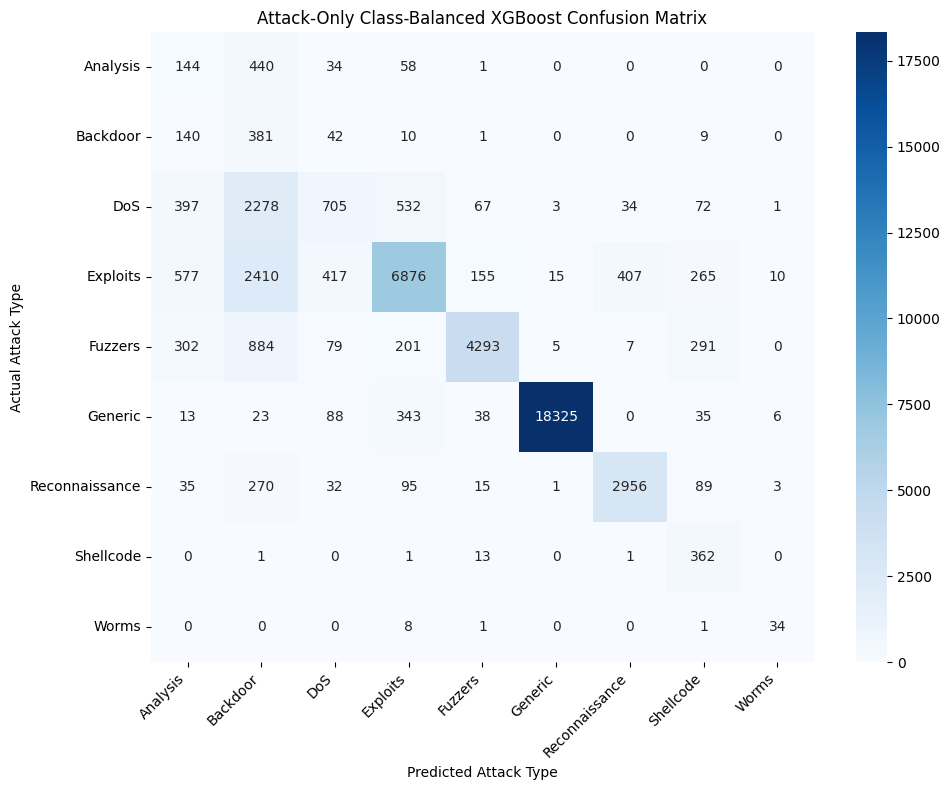

In [106]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

attack_cm = confusion_matrix(
    y_attack_test_encoded,
    attack_balanced_pred
)

plt.figure(figsize=(10, 8))

sns.heatmap(
    attack_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=[
        multi_label_encoder.classes_[i]
        for i in attack_label_encoder.classes_
    ],
    yticklabels=[
        multi_label_encoder.classes_[i]
        for i in attack_label_encoder.classes_
    ]
)

plt.xlabel("Predicted Attack Type")
plt.ylabel("Actual Attack Type")
plt.title("Attack-Only Class-Balanced XGBoost Confusion Matrix")

plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()

plt.savefig(
    "/content/attack_only_balanced_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

<Figure size 1200x600 with 0 Axes>

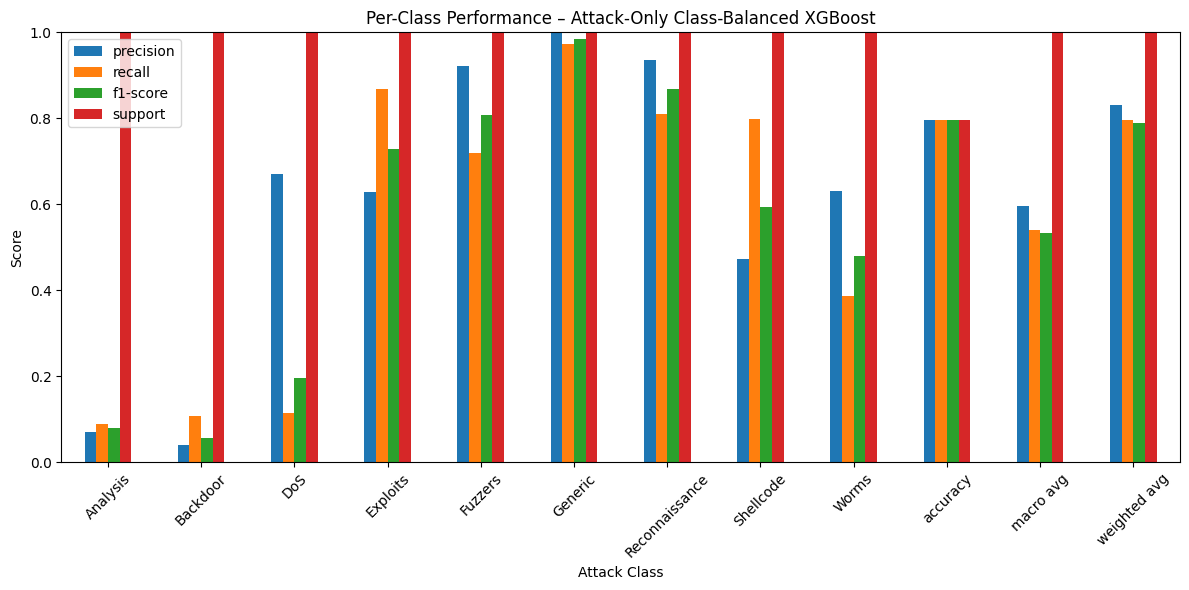

In [107]:
plt.figure(figsize=(12, 6))

attack_report_df.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Per-Class Performance – Attack-Only Class-Balanced XGBoost")
plt.xlabel("Attack Class")
plt.ylabel("Score")
plt.xticks(rotation=45)
plt.ylim(0, 1)

plt.tight_layout()

plt.savefig(
    "/content/attack_only_per_class_performance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [108]:
final_model_comparison = pd.DataFrame({
    "Model": [
        "Standard 10-Class XGBoost",
        "Class-Balanced 10-Class XGBoost",
        "Tuned Class-Balanced 10-Class XGBoost",
        "Standard Attack-Only XGBoost",
        "Final Attack-Only Class-Balanced XGBoost"
    ],
    "Accuracy": [
        0.7677,
        0.6884,
        0.6757,
        0.7969,
        attack_balanced_accuracy
    ],
    "Weighted Precision": [
        0.8389,
        0.8641,
        0.8662,
        0.8319,
        attack_balanced_precision
    ],
    "Weighted Recall": [
        0.7677,
        0.6884,
        0.6757,
        0.7969,
        attack_balanced_recall
    ],
    "Weighted F1": [
        0.7812,
        0.7421,
        0.7319,
        0.7893,
        attack_balanced_f1_weighted
    ],
    "Macro F1": [
        0.5093,
        0.5206,
        0.5023,
        0.5326,
        attack_balanced_f1_macro
    ]
})

display(
    final_model_comparison.round(4)
)

,Model,Accuracy,Weighted Precision,Weighted Recall,Weighted F1,Macro F1
0,Standard 10-Class XGBoost,0.7677,0.8389,0.7677,0.7812,0.5093
1,Class-Balanced 10-Class XGBoost,0.6884,0.8641,0.6884,0.7421,0.5206
2,Tuned Class-Balanced 10-Class XGBoost,0.6757,0.8662,0.6757,0.7319,0.5023
3,Standard Attack-Only XGBoost,0.7969,0.8319,0.7969,0.7893,0.5326
4,Final Attack-Only Class-Balanced XGBoost,0.7517,0.8667,0.7517,0.7903,0.5584


In [109]:
import joblib

joblib.dump(
    attack_balanced_xgb,
    "/content/final_attack_multiclass_xgboost.pkl"
)

joblib.dump(
    attack_label_encoder,
    "/content/attack_label_encoder.pkl"
)

print("Final model saved successfully.")
print("Model: final_attack_multiclass_xgboost.pkl")
print("Encoder: attack_label_encoder.pkl")

Final model saved successfully.
Model: final_attack_multiclass_xgboost.pkl
Encoder: attack_label_encoder.pkl


In [111]:
!pip install shap -q

In [112]:
import shap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("SHAP version:", shap.__version__)

SHAP version: 0.52.0


In [113]:
print("Number of features:", X_attack_test.shape[1])

Number of features: 194


In [114]:
feature_names = [
    f"Feature_{i}"
    for i in range(X_attack_test.shape[1])
]

print(feature_names[:10])
print("Total features:", len(feature_names))

['Feature_0', 'Feature_1', 'Feature_2', 'Feature_3', 'Feature_4', 'Feature_5', 'Feature_6', 'Feature_7', 'Feature_8', 'Feature_9']
Total features: 194


In [115]:
X_shap = X_attack_test[:500]

print("SHAP dataset shape:", X_shap.shape)

SHAP dataset shape: (500, 194)


In [117]:
print([name for name in globals() if "attack" in name.lower() and "model" in name.lower()])

['attack_xgb_model']


In [118]:
explainer = shap.TreeExplainer(
    attack_xgb_model
)

In [119]:
X_shap = X_attack_test[:500]

print("=" * 70)
print("SHAP INPUT")
print("=" * 70)

print("Shape:", X_shap.shape)

SHAP INPUT
Shape: (500, 194)


In [120]:
print("=" * 70)
print("CALCULATING SHAP VALUES")
print("=" * 70)

shap_values = explainer.shap_values(X_shap)

print("SHAP values calculated successfully.")

if isinstance(shap_values, list):
    print("Number of classes:", len(shap_values))
    for i, values in enumerate(shap_values):
        print(
            f"Class {i} ({multi_label_encoder.classes_[attack_label_encoder.classes_[i]]}) :",
            values.shape
        )
else:
    print("SHAP values shape:", np.array(shap_values).shape)

CALCULATING SHAP VALUES
SHAP values calculated successfully.
SHAP values shape: (500, 194, 9)


In [121]:
print("=" * 70)
print("GLOBAL SHAP FEATURE IMPORTANCE")
print("=" * 70)

# Convert SHAP values to absolute importance
shap_abs = np.abs(shap_values)

# Average across:
# 500 samples
# 9 attack classes
global_shap_importance = shap_abs.mean(axis=(0, 2))

# Create feature names
feature_names = [
    f"Feature_{i}"
    for i in range(X_shap.shape[1])
]

# Create importance dataframe
shap_importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Mean |SHAP|": global_shap_importance
})

# Sort
shap_importance_df = shap_importance_df.sort_values(
    "Mean |SHAP|",
    ascending=False
).reset_index(drop=True)

print("\nTop 20 Most Important Features:\n")

display(
    shap_importance_df.head(20).round(6)
)

GLOBAL SHAP FEATURE IMPORTANCE

Top 20 Most Important Features:



,Feature,Mean |SHAP|
0,Feature_158,0.573892
1,Feature_178,0.417493
2,Feature_119,0.256788
3,Feature_133,0.236981
4,Feature_159,0.216941
5,Feature_187,0.205484
6,Feature_161,0.170614
7,Feature_165,0.155145
8,Feature_185,0.153157
9,Feature_138,0.141630


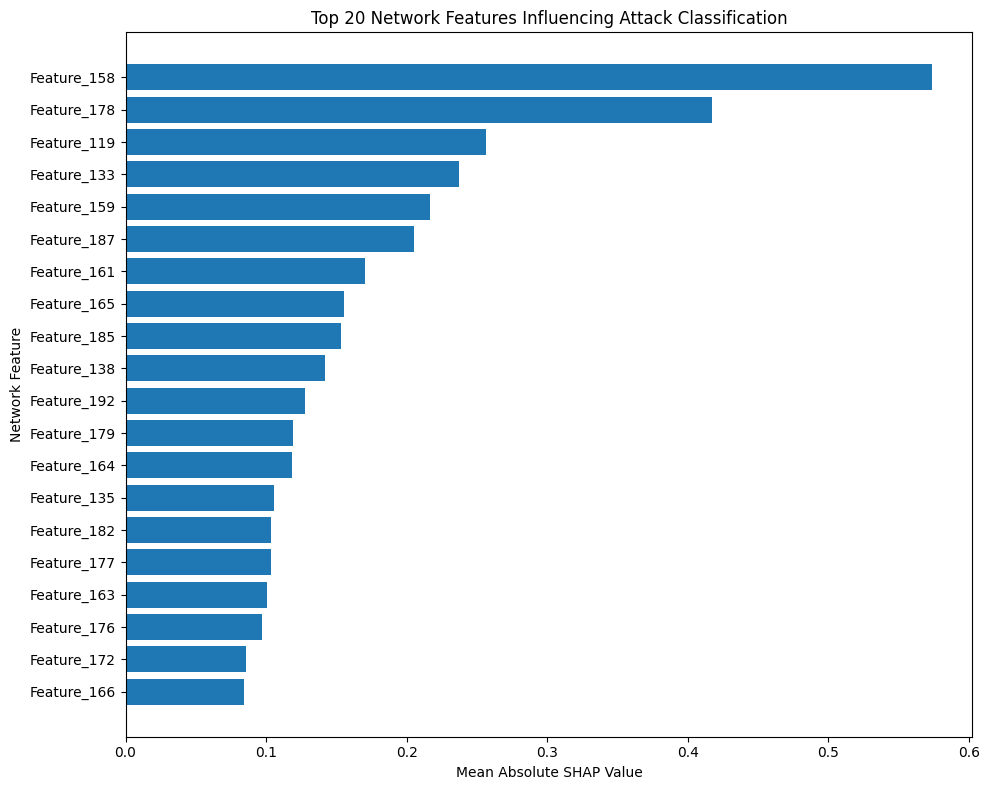

In [122]:
plt.figure(figsize=(10, 8))

top_features = shap_importance_df.head(20).sort_values(
    "Mean |SHAP|"
)

plt.barh(
    top_features["Feature"],
    top_features["Mean |SHAP|"]
)

plt.xlabel("Mean Absolute SHAP Value")
plt.ylabel("Network Feature")
plt.title(
    "Top 20 Network Features Influencing Attack Classification"
)

plt.tight_layout()

plt.savefig(
    "/content/shap_global_feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [123]:
print("=" * 70)
print("CREATING THREAT SEVERITY / RISK SCORING SYSTEM")
print("=" * 70)

# Base severity assigned to each attack type
attack_severity_map = {
    "Analysis": "Low",
    "Fuzzers": "Medium",
    "Reconnaissance": "Medium",
    "Generic": "Medium",
    "DoS": "High",
    "Exploits": "High",
    "Backdoor": "Critical",
    "Shellcode": "Critical",
    "Worms": "Critical"
}

# Numerical severity score
severity_score_map = {
    "Low": 1,
    "Medium": 2,
    "High": 3,
    "Critical": 4
}

print("\nAttack Severity Mapping:")

for attack, severity in attack_severity_map.items():
    print(f"{attack:20s} -> {severity}")

CREATING THREAT SEVERITY / RISK SCORING SYSTEM

Attack Severity Mapping:
Analysis             -> Low
Fuzzers              -> Medium
Reconnaissance       -> Medium
Generic              -> Medium
DoS                  -> High
Exploits             -> High
Backdoor             -> Critical
Shellcode            -> Critical
Worms                -> Critical


In [124]:
def calculate_risk_score(attack_type, confidence):

    base_severity = attack_severity_map.get(
        attack_type,
        "Medium"
    )

    base_score = severity_score_map[base_severity]

    # Confidence adjustment
    if confidence >= 0.90:
        confidence_factor = 1.0
    elif confidence >= 0.75:
        confidence_factor = 0.9
    elif confidence >= 0.60:
        confidence_factor = 0.75
    else:
        confidence_factor = 0.60

    risk_score = base_score * confidence_factor

    # Convert numerical score to final risk level
    if risk_score >= 3.5:
        risk_level = "Critical"
    elif risk_score >= 2.5:
        risk_level = "High"
    elif risk_score >= 1.5:
        risk_level = "Medium"
    else:
        risk_level = "Low"

    return risk_score, risk_level

In [125]:
import numpy as np
import pandas as pd

risk_results = []

for i in range(len(attack_balanced_pred)):

    predicted_class_id = attack_balanced_pred[i]

    attack_type = multi_label_encoder.classes_[
        attack_label_encoder.classes_[predicted_class_id]
    ]

    confidence = np.max(
        attack_balanced_probability[i]
    )

    risk_score, risk_level = calculate_risk_score(
        attack_type,
        confidence
    )

    risk_results.append({
        "Attack Type": attack_type,
        "Confidence": confidence,
        "Risk Score": risk_score,
        "Risk Level": risk_level
    })

risk_df = pd.DataFrame(risk_results)

print("=" * 70)
print("THREAT RISK SCORING COMPLETED")
print("=" * 70)

print("\nNumber of scored attacks:", len(risk_df))

risk_df.head(10)

THREAT RISK SCORING COMPLETED

Number of scored attacks: 45332


,Attack Type,Confidence,Risk Score,Risk Level
0,Backdoor,0.433639,2.4,Medium
1,Backdoor,0.433639,2.4,Medium
2,Backdoor,0.433639,2.4,Medium
3,Backdoor,0.433639,2.4,Medium
4,Analysis,0.305024,0.6,Low
5,Backdoor,0.280914,2.4,Medium
6,Backdoor,0.280914,2.4,Medium
7,Backdoor,0.280914,2.4,Medium
8,Backdoor,0.280914,2.4,Medium
9,Shellcode,0.991981,4.0,Critical


In [126]:
print("=" * 70)
print("THREAT RISK DISTRIBUTION")
print("=" * 70)

risk_distribution = risk_df["Risk Level"].value_counts()

print(risk_distribution)

THREAT RISK DISTRIBUTION
Risk Level
Medium      34896
High         6812
Low          2174
Critical     1450
Name: count, dtype: int64


In [127]:
print("\nPercentage Distribution:")

risk_percentage = (
    risk_df["Risk Level"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print(risk_percentage)


Percentage Distribution:
Risk Level
Medium      76.98
High        15.03
Low          4.80
Critical     3.20
Name: proportion, dtype: float64


In [128]:
risk_by_attack = pd.crosstab(
    risk_df["Attack Type"],
    risk_df["Risk Level"]
)

print("=" * 70)
print("ATTACK TYPE VS RISK LEVEL")
print("=" * 70)

print(risk_by_attack)

ATTACK TYPE VS RISK LEVEL
Risk Level      Critical  High   Low  Medium
Attack Type                                 
Analysis               0     0  1608       0
Backdoor             624   482     0    5581
DoS                    0   286     0    1111
Exploits               0  5861     0    2263
Fuzzers                0     0   238    4346
Generic                0     0    85   18264
Reconnaissance         0     0   243    3162
Shellcode            785   182     0     157
Worms                 41     1     0      12


In [129]:
def generate_security_alert(attack_type, confidence, risk_level):

    if risk_level == "Critical":
        priority = "IMMEDIATE ACTION"
    elif risk_level == "High":
        priority = "HIGH PRIORITY"
    elif risk_level == "Medium":
        priority = "MONITOR"
    else:
        priority = "LOW PRIORITY"

    alert = {
        "Threat": attack_type,
        "Confidence": round(confidence * 100, 2),
        "Risk Level": risk_level,
        "Priority": priority
    }

    return alert

In [130]:
sample_alert = generate_security_alert(
    risk_df.iloc[0]["Attack Type"],
    risk_df.iloc[0]["Confidence"],
    risk_df.iloc[0]["Risk Level"]
)

print("=" * 70)
print("SAMPLE SECURITY ALERT")
print("=" * 70)

for key, value in sample_alert.items():
    print(f"{key:15s}: {value}")

SAMPLE SECURITY ALERT
Threat         : Backdoor
Confidence     : 43.36000061035156
Risk Level     : Medium
Priority       : MONITOR


In [131]:
# ============================================================
# EXPORT RESULTS FOR STREAMLIT DASHBOARD
# ============================================================

import os

os.makedirs("dashboard_data", exist_ok=True)

# Export risk results
risk_df.to_csv(
    "dashboard_data/risk_results.csv",
    index=False
)

print("Risk results exported successfully.")

# Export attack distribution
attack_distribution = (
    risk_df["Attack Type"]
    .value_counts()
    .reset_index()
)

attack_distribution.columns = [
    "Attack Type",
    "Count"
]

attack_distribution.to_csv(
    "dashboard_data/attack_distribution.csv",
    index=False
)

# Export risk distribution
risk_distribution_df = (
    risk_df["Risk Level"]
    .value_counts()
    .reset_index()
)

risk_distribution_df.columns = [
    "Risk Level",
    "Count"
]

risk_distribution_df.to_csv(
    "dashboard_data/risk_distribution.csv",
    index=False
)

print("Dashboard files created.")

Risk results exported successfully.
Dashboard files created.


In [133]:
# ============================================================
# CREATE TOP SHAP FEATURE IMPORTANCE
# ============================================================

import numpy as np
import pandas as pd

# Calculate mean absolute SHAP across:
# samples and attack classes
mean_abs_shap = np.abs(shap_values).mean(axis=(0, 2))

# Get indices of top 20 features
top_indices = np.argsort(
    mean_abs_shap
)[::-1][:20]

# Create feature names
top_features = [
    f"Feature_{i}"
    for i in top_indices
]

# Corresponding SHAP values
top_shap_values = mean_abs_shap[
    top_indices
]

# Create dataframe
shap_export = pd.DataFrame({
    "Feature": top_features,
    "Mean Absolute SHAP": top_shap_values
})

print("=" * 70)
print("TOP 20 SHAP FEATURES")
print("=" * 70)

print(shap_export)

TOP 20 SHAP FEATURES
        Feature  Mean Absolute SHAP
0   Feature_158            0.573892
1   Feature_178            0.417493
2   Feature_119            0.256788
3   Feature_133            0.236981
4   Feature_159            0.216941
5   Feature_187            0.205484
6   Feature_161            0.170614
7   Feature_165            0.155145
8   Feature_185            0.153157
9   Feature_138            0.141630
10  Feature_192            0.127436
11  Feature_179            0.118908
12  Feature_164            0.118372
13  Feature_135            0.105733
14  Feature_182            0.103513
15  Feature_177            0.103304
16  Feature_163            0.100557
17  Feature_176            0.097068
18  Feature_172            0.085855
19  Feature_166            0.084638


In [134]:
# ============================================================
# EXPORT SHAP FEATURE IMPORTANCE
# ============================================================

import os

os.makedirs("dashboard_data", exist_ok=True)

shap_export.to_csv(
    "dashboard_data/shap_feature_importance.csv",
    index=False
)

print("SHAP feature importance exported successfully.")

SHAP feature importance exported successfully.


In [135]:
import os

print(
    os.path.exists(
        "dashboard_data/shap_feature_importance.csv"
    )
)

True


In [136]:
pd.read_csv(
    "dashboard_data/shap_feature_importance.csv"
).head(20)

,Feature,Mean Absolute SHAP
0,Feature_158,0.573892
1,Feature_178,0.417493
2,Feature_119,0.256788
3,Feature_133,0.236981
4,Feature_159,0.216941
5,Feature_187,0.205484
6,Feature_161,0.170614
7,Feature_165,0.155145
8,Feature_185,0.153157
9,Feature_138,0.141630


In [137]:
import joblib
import os

os.makedirs("dashboard_data", exist_ok=True)

# Save trained attack classification model
joblib.dump(
    attack_xgb_model,
    "dashboard_data/attack_xgb_model.pkl"
)

print("Attack XGBoost model exported successfully.")

Attack XGBoost model exported successfully.


In [139]:
import joblib
import os

os.makedirs("dashboard_data", exist_ok=True)

# Save trained attack classification model
joblib.dump(
    attack_xgb_model,
    "dashboard_data/attack_xgb_model.pkl"
)

# X_attack_train is a NumPy array
feature_names = [
    f"Feature_{i}"
    for i in range(X_attack_train.shape[1])
]

joblib.dump(
    feature_names,
    "dashboard_data/feature_names.pkl"
)

print("Attack XGBoost model exported successfully.")
print("Feature names exported successfully.")
print("Number of features:", len(feature_names))

Attack XGBoost model exported successfully.
Feature names exported successfully.
Number of features: 194
